# Feature Engineering

---

1. Import packages
2. Load data
3. Feature engineering

---

## 1. Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

pd.set_option('display.max_rows', None)

---
## 2. Load data

In [3]:
client_clean_df = pd.read_csv('clean_data_after_eda.csv')
client_clean_df["date_activ"] = pd.to_datetime(client_clean_df["date_activ"], format='%Y-%m-%d')
client_clean_df["date_end"] = pd.to_datetime(client_clean_df["date_end"], format='%Y-%m-%d')
client_clean_df["date_modif_prod"] = pd.to_datetime(client_clean_df["date_modif_prod"], format='%Y-%m-%d')
client_clean_df["date_renewal"] = pd.to_datetime(client_clean_df["date_renewal"], format='%Y-%m-%d')

In [4]:
client_clean_df.shape

(14606, 44)

In [5]:
client_clean_df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,0.000131,4.100838e-05,0.000908,2.086294,99.530517,44.235794,2.086425,9.953056e+01,44.236702,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000003,1.217891e-03,0.000000,0.009482,0.000000,0.000000,0.009485,1.217891e-03,0.000000,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000004,9.450150e-08,0.000000,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000,0


# Functions

In [6]:
def null_features(df):
    # Prepare dataset EDA values
    summary = pd.DataFrame(df.dtypes, columns=['dtypes']).reset_index()
    summary['Name'] = summary['index']
    summary = summary[['Name', 'dtypes']]

    # Function to safely count uniques, ignoring columns with unhashable types (like lists)
    def safe_nunique(col):
        try:
            return col.nunique()
        except TypeError:
            return None  # or np.nan if you prefer

    # Calculate uniques with safe check
    summary['Uniques'] = summary['Name'].apply(lambda col_name: safe_nunique(df[col_name]))
    summary['Null'] = df.isna().sum().values
    summary['Null(%)'] = round((summary['Null'] / len(df) * 100), 1).astype(str) + '%'

    # Add a column to indicate whether the feature has missing values
    summary['Has Null'] = summary['Null'] > 0

    # Sort by Null count (descending) and Name (ascending)
    summary = summary.sort_values(by=['Null', 'Name'], ascending=[False, True]).reset_index(drop=True)
    summary.index = range(1, len(summary) + 1)

    return summary


---

## 3. Feature engineering

### Difference between off-peak prices in December and preceding January

Below is the code created by your colleague to calculate the feature described above. Use this code to re-create this feature and then think about ways to build on this feature to create features with a higher predictive power.

In [7]:
price_df = pd.read_csv('../task2/price_data (1).csv')
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format='%Y-%m-%d')
price_df.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [8]:
price_df.shape

(193002, 8)

In [9]:
# IDs present in price_df but not in client_clean_df
price_only = set(price_df['id'].unique()) - set(client_clean_df['id'].unique())

# IDs present in client_clean_df but not in price_df
client_clean_df_only = set(client_clean_df['id'].unique()) - set(price_df['id'].unique())

print("IDs present in price_df but not in client_clean_df:", len(price_only))
print("IDs present in client_df but not in client_clean_df:", len(client_clean_df_only))

IDs present in price_df but not in client_clean_df: 1490
IDs present in client_df but not in client_clean_df: 0


Observation:

- price_df has 16,096 unique customer IDs, whereas client_clean_df has 14,606 unique customer IDs. and All 14,606 IDs in client_df are also present in price_df. 
- This means price_df contains 1,490 more unique IDs than client_df.    

# Working on price_df dataframe

In [10]:
price_df.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [11]:
price_df.shape

(193002, 8)

## Create temporary dataframe

In [12]:
temp_df = pd.DataFrame()

In [13]:
temp_df.shape

(0, 0)

In [14]:
# Calculate mean price for each customer
mean_price_df = price_df.drop(columns=['price_date']).groupby('id').agg(
    mean_year_off_peak_var=('price_off_peak_var', 'mean'),
    mean_year_off_peak_fix=('price_off_peak_fix', 'mean'),
    mean_year_peak_var=('price_peak_var', 'mean'),
    mean_year_peak_fix=('price_peak_fix', 'mean'),
    mean_year_mid_peak_var=('price_mid_peak_var', 'mean'),
    mean_year_mid_peak_fix=('price_mid_peak_fix', 'mean')
).reset_index()

mean_price_df.head()

,id,mean_year_off_peak_var,mean_year_off_peak_fix,mean_year_peak_var,mean_year_peak_fix,mean_year_mid_peak_var,mean_year_mid_peak_fix
0,0002203ffbb812588b632b9e628cc38d,0.124338,40.701732,0.103794,24.421038,0.073160,16.280694
1,0004351ebdd665e6ee664792efc4fd13,0.146426,44.385450,0.000000,0.000000,0.000000,0.000000
2,0010bcc39e42b3c2131ed2ce55246e3c,0.181558,45.319710,0.000000,0.000000,0.000000,0.000000
3,0010ee3855fdea87602a5b7aba8e42de,0.118757,40.647427,0.098292,24.388455,0.069032,16.258971
4,00114d74e963e47177db89bc70108537,0.147926,44.266930,0.000000,0.000000,0.000000,0.000000


In [15]:
temp_df = mean_price_df

In [16]:
temp_df.shape

(16096, 7)

In [17]:
# Sort price data by customer ID and date
price_df = price_df.sort_values(['id', 'price_date'])

# Calculate December - January price differences
diff_df = price_df.groupby('id').agg(
    dec_jan_off_peak_var_diff=('price_off_peak_var', lambda x: x.iloc[-1] - x.iloc[0]),
    dec_jan_off_peak_fix_diff=('price_off_peak_fix', lambda x: x.iloc[-1] - x.iloc[0]),

    dec_jan_peak_var_diff=('price_peak_var', lambda x: x.iloc[-1] - x.iloc[0]),
    dec_jan_peak_fix_diff=('price_peak_fix', lambda x: x.iloc[-1] - x.iloc[0]),

    dec_jan_mid_peak_var_diff=('price_mid_peak_var', lambda x: x.iloc[-1] - x.iloc[0]),
    dec_jan_mid_peak_fix_diff=('price_mid_peak_fix', lambda x: x.iloc[-1] - x.iloc[0])
).reset_index()

diff_df.head()

,id,dec_jan_off_peak_var_diff,dec_jan_off_peak_fix_diff,dec_jan_peak_var_diff,dec_jan_peak_fix_diff,dec_jan_mid_peak_var_diff,dec_jan_mid_peak_fix_diff
0,0002203ffbb812588b632b9e628cc38d,-0.006192,0.162916,-0.002302,0.097749,0.003487,0.065166
1,0004351ebdd665e6ee664792efc4fd13,-0.004104,0.177779,0.000000,0.000000,0.000000,0.000000
2,0010bcc39e42b3c2131ed2ce55246e3c,0.050443,1.500000,0.000000,0.000000,0.000000,0.000000
3,0010ee3855fdea87602a5b7aba8e42de,-0.010018,0.162916,-0.005120,0.097749,0.000763,0.065166
4,00114d74e963e47177db89bc70108537,-0.003994,-0.000001,0.000000,0.000000,0.000000,0.000000


In [18]:
# Merge with temp_df using customer ID
temp_df = temp_df.merge(
    diff_df,
    on='id',
    how='left'
)

In [19]:
temp_df.shape

(16096, 13)

In [20]:
temp_df.head()

,id,mean_year_off_peak_var,mean_year_off_peak_fix,mean_year_peak_var,mean_year_peak_fix,mean_year_mid_peak_var,mean_year_mid_peak_fix,dec_jan_off_peak_var_diff,dec_jan_off_peak_fix_diff,dec_jan_peak_var_diff,dec_jan_peak_fix_diff,dec_jan_mid_peak_var_diff,dec_jan_mid_peak_fix_diff
0,0002203ffbb812588b632b9e628cc38d,0.124338,40.701732,0.103794,24.421038,0.073160,16.280694,-0.006192,0.162916,-0.002302,0.097749,0.003487,0.065166
1,0004351ebdd665e6ee664792efc4fd13,0.146426,44.385450,0.000000,0.000000,0.000000,0.000000,-0.004104,0.177779,0.000000,0.000000,0.000000,0.000000
2,0010bcc39e42b3c2131ed2ce55246e3c,0.181558,45.319710,0.000000,0.000000,0.000000,0.000000,0.050443,1.500000,0.000000,0.000000,0.000000,0.000000
3,0010ee3855fdea87602a5b7aba8e42de,0.118757,40.647427,0.098292,24.388455,0.069032,16.258971,-0.010018,0.162916,-0.005120,0.097749,0.000763,0.065166
4,00114d74e963e47177db89bc70108537,0.147926,44.266930,0.000000,0.000000,0.000000,0.000000,-0.003994,-0.000001,0.000000,0.000000,0.000000,0.000000


In [21]:
temp_df.shape

(16096, 13)

In [22]:
temp_df['price_off_peak'] = temp_df['mean_year_off_peak_var'] + temp_df['mean_year_off_peak_fix']

temp_df['price_peak'] = temp_df['mean_year_peak_var'] + temp_df['mean_year_peak_fix']

temp_df['price_mid_peak'] = temp_df['mean_year_mid_peak_var'] + temp_df['mean_year_mid_peak_fix']

In [23]:
temp_df['off_peak_peak_var_mean_diff'] = temp_df['mean_year_off_peak_var'] - temp_df['mean_year_peak_var']

temp_df['off_peak_mid_peak_var_mean_diff'] = temp_df['mean_year_off_peak_var'] - temp_df['mean_year_mid_peak_var']

temp_df['peak_mid_peak_var_mean_diff'] = temp_df['mean_year_peak_var'] - temp_df['mean_year_mid_peak_var']

temp_df['off_peak_peak_fix_mean_diff'] = temp_df['mean_year_off_peak_fix'] - temp_df['mean_year_peak_fix']

temp_df['off_peak_mid_peak_fix_mean_diff'] = temp_df['mean_year_off_peak_fix'] - temp_df['mean_year_mid_peak_fix']

temp_df['peak_mid_peak_fix_mean_diff'] = temp_df['mean_year_peak_fix'] - temp_df['mean_year_mid_peak_fix']

In [24]:
temp_df.shape

(16096, 22)

In [25]:
temp_df.columns

Index(['id', 'mean_year_off_peak_var', 'mean_year_off_peak_fix',
       'mean_year_peak_var', 'mean_year_peak_fix', 'mean_year_mid_peak_var',
       'mean_year_mid_peak_fix', 'dec_jan_off_peak_var_diff',
       'dec_jan_off_peak_fix_diff', 'dec_jan_peak_var_diff',
       'dec_jan_peak_fix_diff', 'dec_jan_mid_peak_var_diff',
       'dec_jan_mid_peak_fix_diff', 'price_off_peak', 'price_peak',
       'price_mid_peak', 'off_peak_peak_var_mean_diff',
       'off_peak_mid_peak_var_mean_diff', 'peak_mid_peak_var_mean_diff',
       'off_peak_peak_fix_mean_diff', 'off_peak_mid_peak_fix_mean_diff',
       'peak_mid_peak_fix_mean_diff'],
      dtype='object')

In [26]:
temp_df.head()

,id,mean_year_off_peak_var,mean_year_off_peak_fix,mean_year_peak_var,mean_year_peak_fix,mean_year_mid_peak_var,mean_year_mid_peak_fix,dec_jan_off_peak_var_diff,dec_jan_off_peak_fix_diff,dec_jan_peak_var_diff,...,dec_jan_mid_peak_fix_diff,price_off_peak,price_peak,price_mid_peak,off_peak_peak_var_mean_diff,off_peak_mid_peak_var_mean_diff,peak_mid_peak_var_mean_diff,off_peak_peak_fix_mean_diff,off_peak_mid_peak_fix_mean_diff,peak_mid_peak_fix_mean_diff
0,0002203ffbb812588b632b9e628cc38d,0.124338,40.701732,0.103794,24.421038,0.073160,16.280694,-0.006192,0.162916,-0.002302,...,0.065166,40.826071,24.524832,16.353854,0.020545,0.051178,0.030633,16.280694,24.421038,8.140345
1,0004351ebdd665e6ee664792efc4fd13,0.146426,44.385450,0.000000,0.000000,0.000000,0.000000,-0.004104,0.177779,0.000000,...,0.000000,44.531877,0.000000,0.000000,0.146426,0.146426,0.000000,44.385450,44.385450,0.000000
2,0010bcc39e42b3c2131ed2ce55246e3c,0.181558,45.319710,0.000000,0.000000,0.000000,0.000000,0.050443,1.500000,0.000000,...,0.000000,45.501268,0.000000,0.000000,0.181558,0.181558,0.000000,45.319710,45.319710,0.000000
3,0010ee3855fdea87602a5b7aba8e42de,0.118757,40.647427,0.098292,24.388455,0.069032,16.258971,-0.010018,0.162916,-0.005120,...,0.065166,40.766185,24.486748,16.328003,0.020465,0.049725,0.029260,16.258972,24.388456,8.129484
4,00114d74e963e47177db89bc70108537,0.147926,44.266930,0.000000,0.000000,0.000000,0.000000,-0.003994,-0.000001,0.000000,...,0.000000,44.414856,0.000000,0.000000,0.147926,0.147926,0.000000,44.266930,44.266930,0.000000


## Combine client_clean_df and temp_df column

In [27]:
df = client_clean_df.merge(
    temp_df,
    on='id',
    how='left'
)

In [28]:
df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,dec_jan_mid_peak_fix_diff,price_off_peak,price_peak,price_mid_peak,off_peak_peak_var_mean_diff,off_peak_mid_peak_var_mean_diff,peak_mid_peak_var_mean_diff,off_peak_peak_fix_mean_diff,off_peak_mid_peak_fix_mean_diff,peak_mid_peak_fix_mean_diff
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,-16.226389,41.067053,22.452760,14.967871,0.024038,0.058257,0.034219,18.590255,26.040925,7.450670
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000000,44.460984,0.007124,0.000000,0.142485,0.149609,0.007124,44.311375,44.311375,0.000000
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000000,44.555962,0.088421,0.000000,0.082090,0.170512,0.088421,44.385450,44.385450,0.000000
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,0.000000,44.551475,0.000000,0.000000,0.151210,0.151210,0.000000,44.400265,44.400265,0.000000
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,0.065166,40.812330,24.516531,16.348129,0.020536,0.051309,0.030773,16.275263,24.412893,8.137629


In [29]:
df.columns

Index(['id', 'channel_sales', 'cons_12m', 'cons_gas_12m', 'cons_last_month',
       'date_activ', 'date_end', 'date_modif_prod', 'date_renewal',
       'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy',
       'forecast_meter_rent_12m', 'forecast_price_energy_off_peak',
       'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'has_gas',
       'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act',
       'net_margin', 'num_years_antig', 'origin_up', 'pow_max',
       'var_year_price_off_peak_var', 'var_year_price_peak_var',
       'var_year_price_mid_peak_var', 'var_year_price_off_peak_fix',
       'var_year_price_peak_fix', 'var_year_price_mid_peak_fix',
       'var_year_price_off_peak', 'var_year_price_peak',
       'var_year_price_mid_peak', 'var_6m_price_off_peak_var',
       'var_6m_price_peak_var', 'var_6m_price_mid_peak_var',
       'var_6m_price_off_peak_fix', 'var_6m_price_peak_fix',
       'var_6m_price_mid_peak_fix', 'var_6m_p

In [30]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
cons_12m,14606.0,159220.286252,0.0,5674.75,14115.5,40763.75,6207104.0,573465.264198
cons_gas_12m,14606.0,28092.375325,0.0,0.0,0.0,0.0,4154590.0,162973.059057
cons_last_month,14606.0,16090.269752,0.0,0.0,792.5,3383.0,771203.0,64364.196422
date_activ,14606,2011-01-28 07:54:18.879912448,2003-05-09 00:00:00,2010-01-15 00:00:00,2011-03-04 00:00:00,2012-04-19 00:00:00,2014-09-01 00:00:00,NaN
date_end,14606,2016-07-27 20:48:26.422018560,2016-01-28 00:00:00,2016-04-27 06:00:00,2016-08-01 00:00:00,2016-10-31 00:00:00,2017-06-13 00:00:00,NaN
date_modif_prod,14606,2013-01-02 12:29:10.951663872,2003-05-09 00:00:00,2010-08-12 00:00:00,2013-06-19 00:00:00,2015-06-16 00:00:00,2016-01-29 00:00:00,NaN
date_renewal,14606,2015-07-21 06:59:00.353279488,2013-06-26 00:00:00,2015-04-17 00:00:00,2015-07-27 00:00:00,2015-10-29 00:00:00,2016-01-28 00:00:00,NaN
forecast_cons_12m,14606.0,1868.61488,0.0,494.995,1112.875,2401.79,82902.83,2387.571531
forecast_cons_year,14606.0,1399.762906,0.0,0.0,314.0,1745.75,175375.0,3247.786255
forecast_discount_energy,14606.0,0.966726,0.0,0.0,0.0,0.0,30.0,5.108289


In [31]:
df.drop(columns=['id']).skew(numeric_only=True).sort_values(ascending=False)

net_margin                         36.569515
var_6m_price_off_peak_fix          22.886924
var_6m_price_off_peak              22.886911
var_year_price_off_peak_fix        22.051551
var_year_price_off_peak            22.051457
var_6m_price_off_peak_var          16.954975
forecast_cons_year                 16.587990
imp_cons                           13.198799
var_year_price_off_peak_var        12.052339
var_6m_price_peak                  10.721069
var_6m_price_peak_fix              10.721053
var_6m_price_mid_peak_var          10.072325
var_6m_price_mid_peak_fix           9.862636
var_6m_price_mid_peak               9.862635
cons_gas_12m                        9.597530
var_year_price_peak_var             8.979052
var_6m_price_peak_var               8.948396
var_year_price_mid_peak_var         8.720249
nb_prod_act                         8.636878
var_year_price_peak                 7.908207
var_year_price_peak_fix             7.908174
var_year_price_mid_peak             7.907295
var_year_p

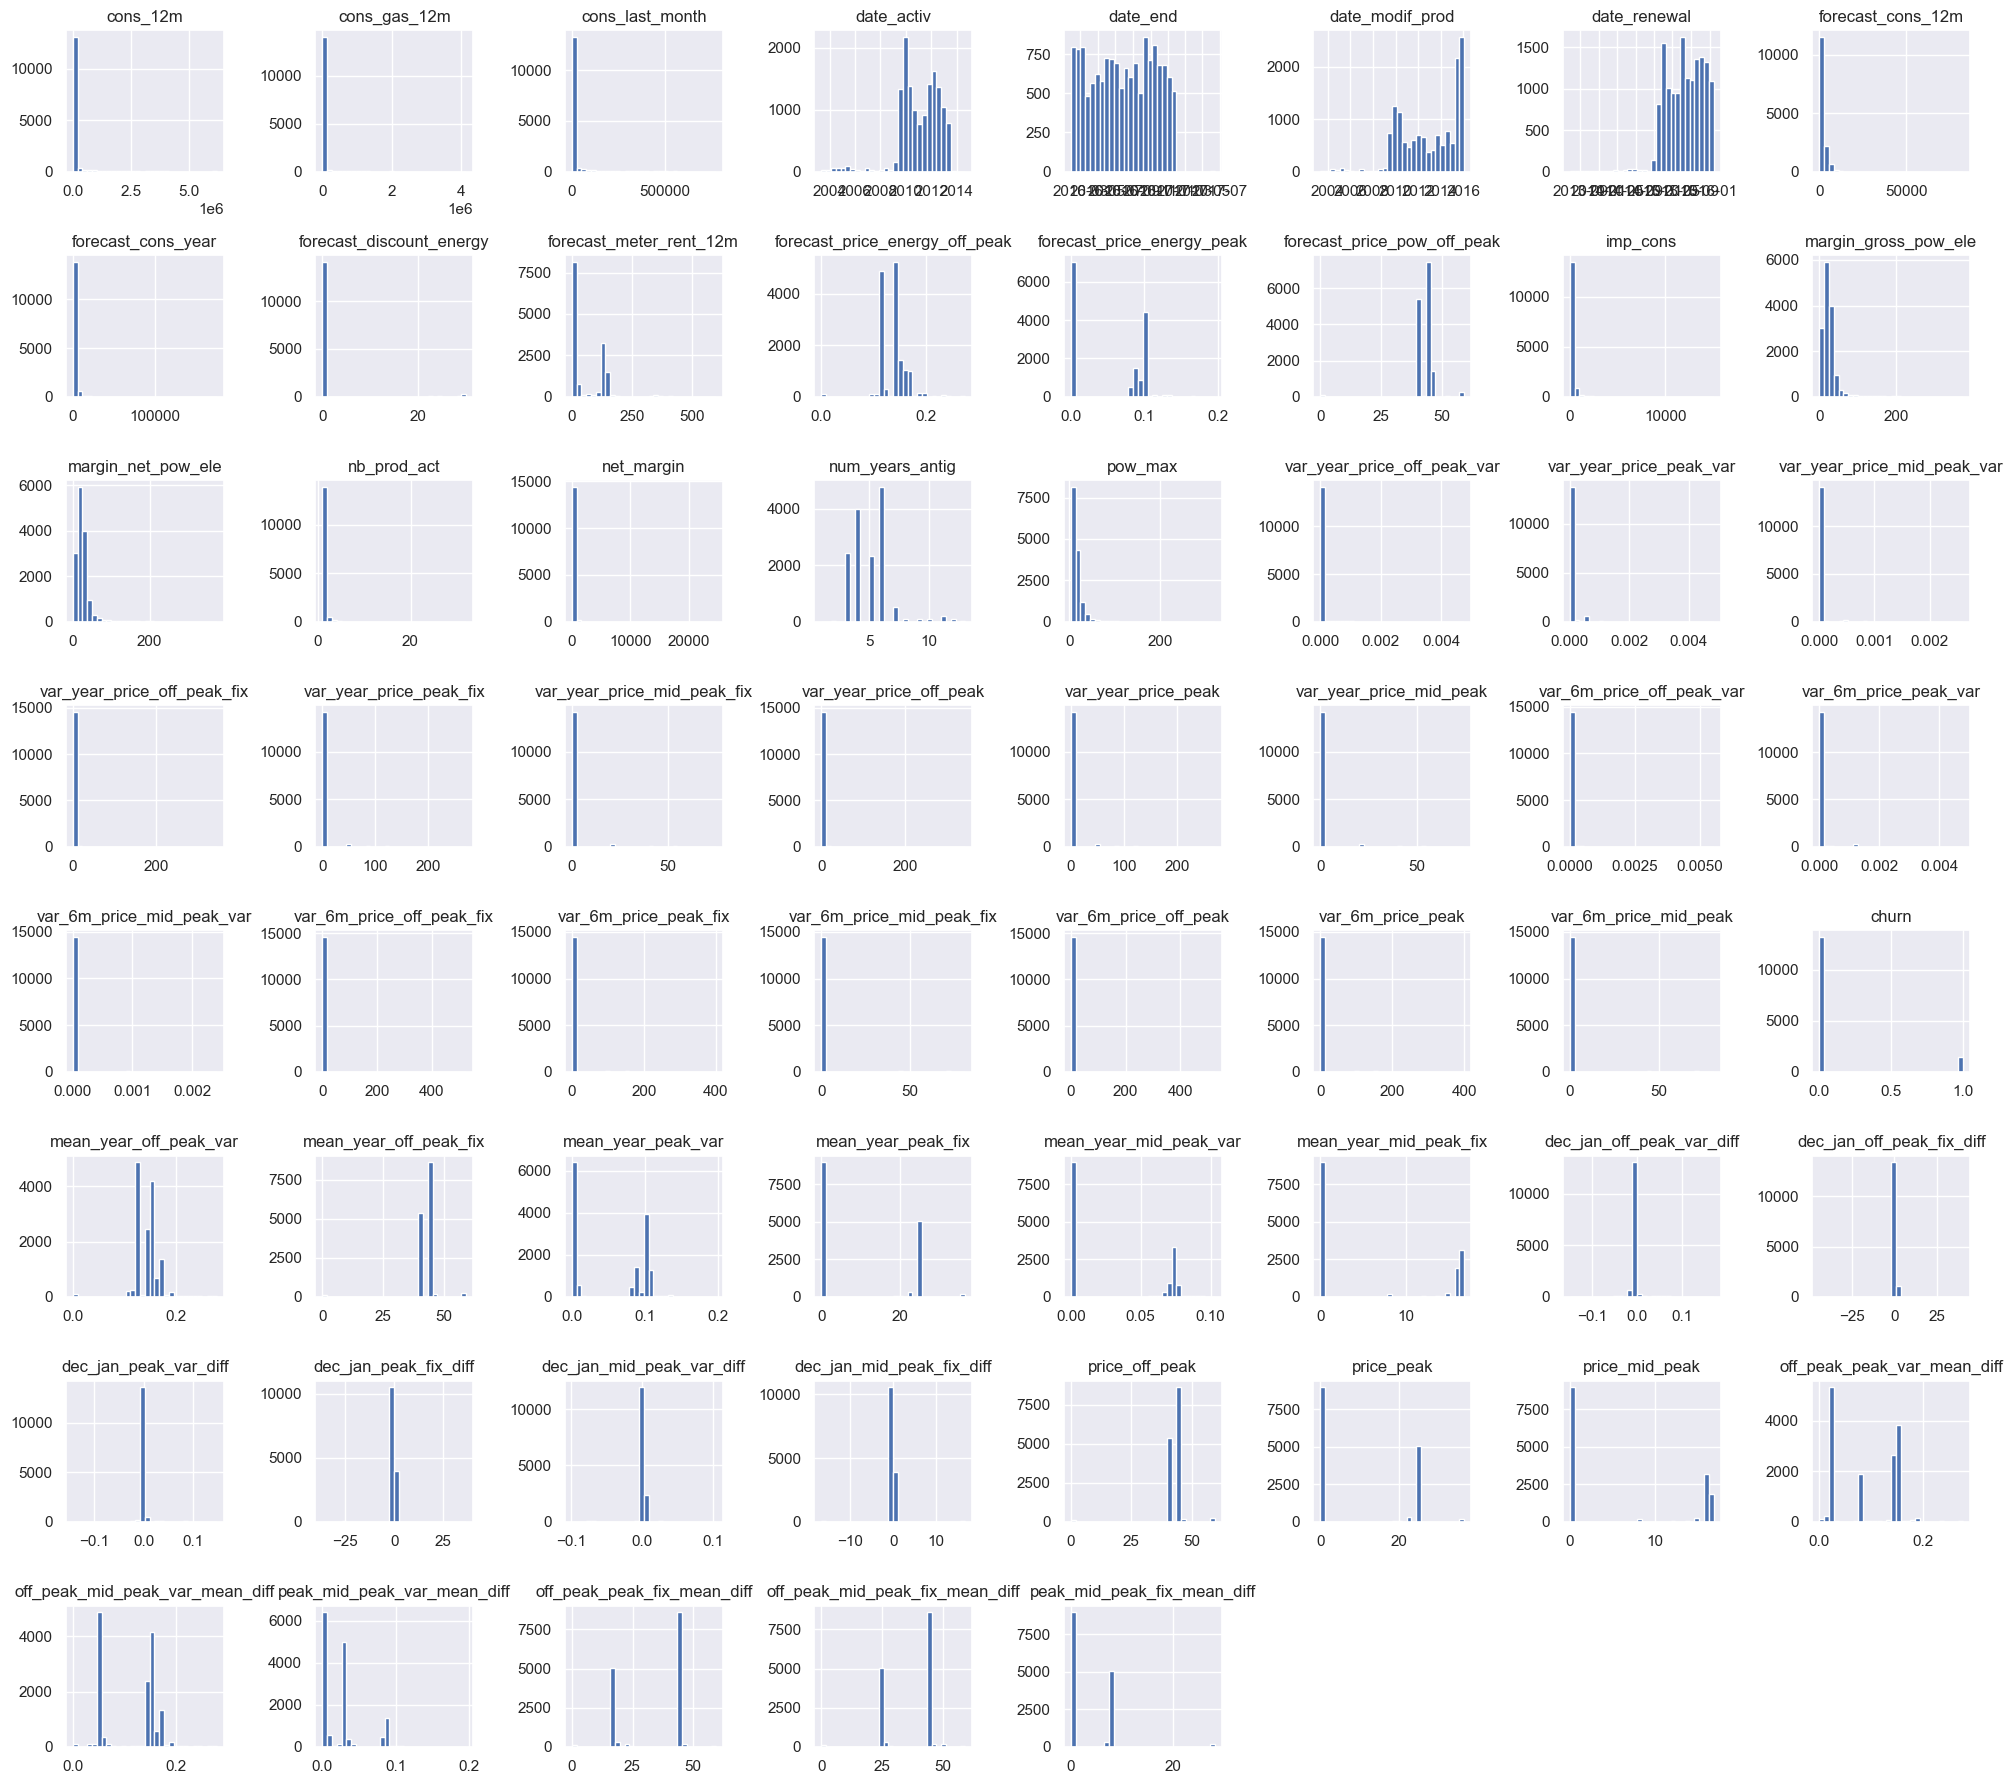

In [32]:
df.drop(columns=['id']).hist(figsize=(20, 18), bins=30)
plt.tight_layout()
plt.show()

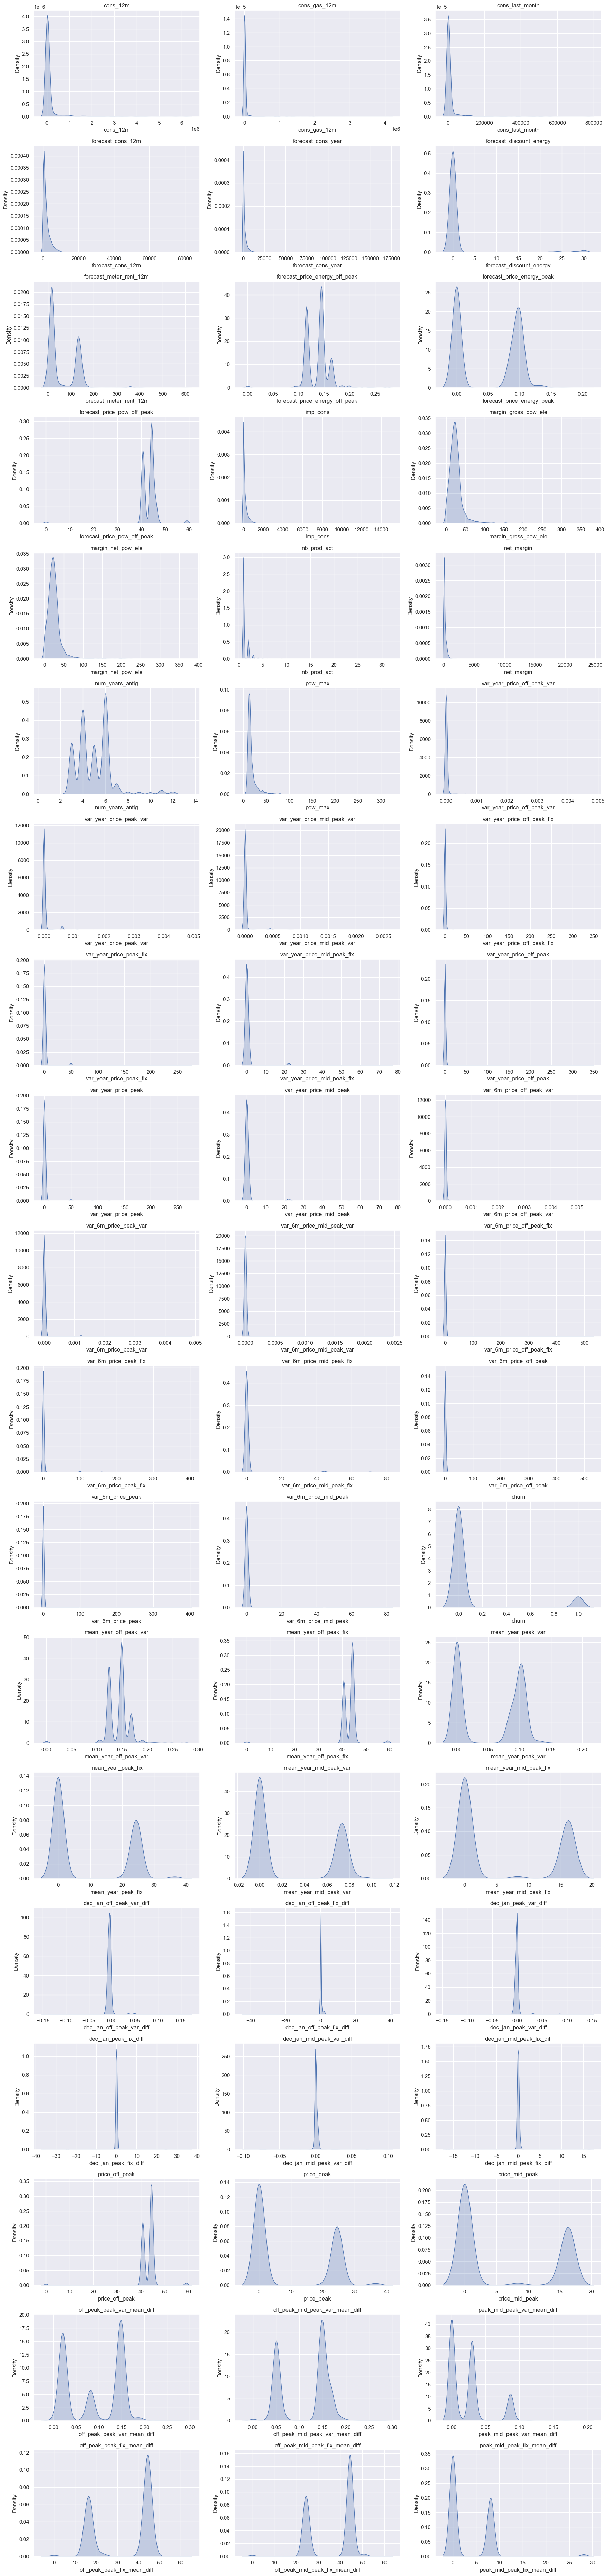

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

cols = df.select_dtypes(include='number').columns

n_cols = 3
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.kdeplot(data=df, x=col, fill=True, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')

for i in range(len(cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

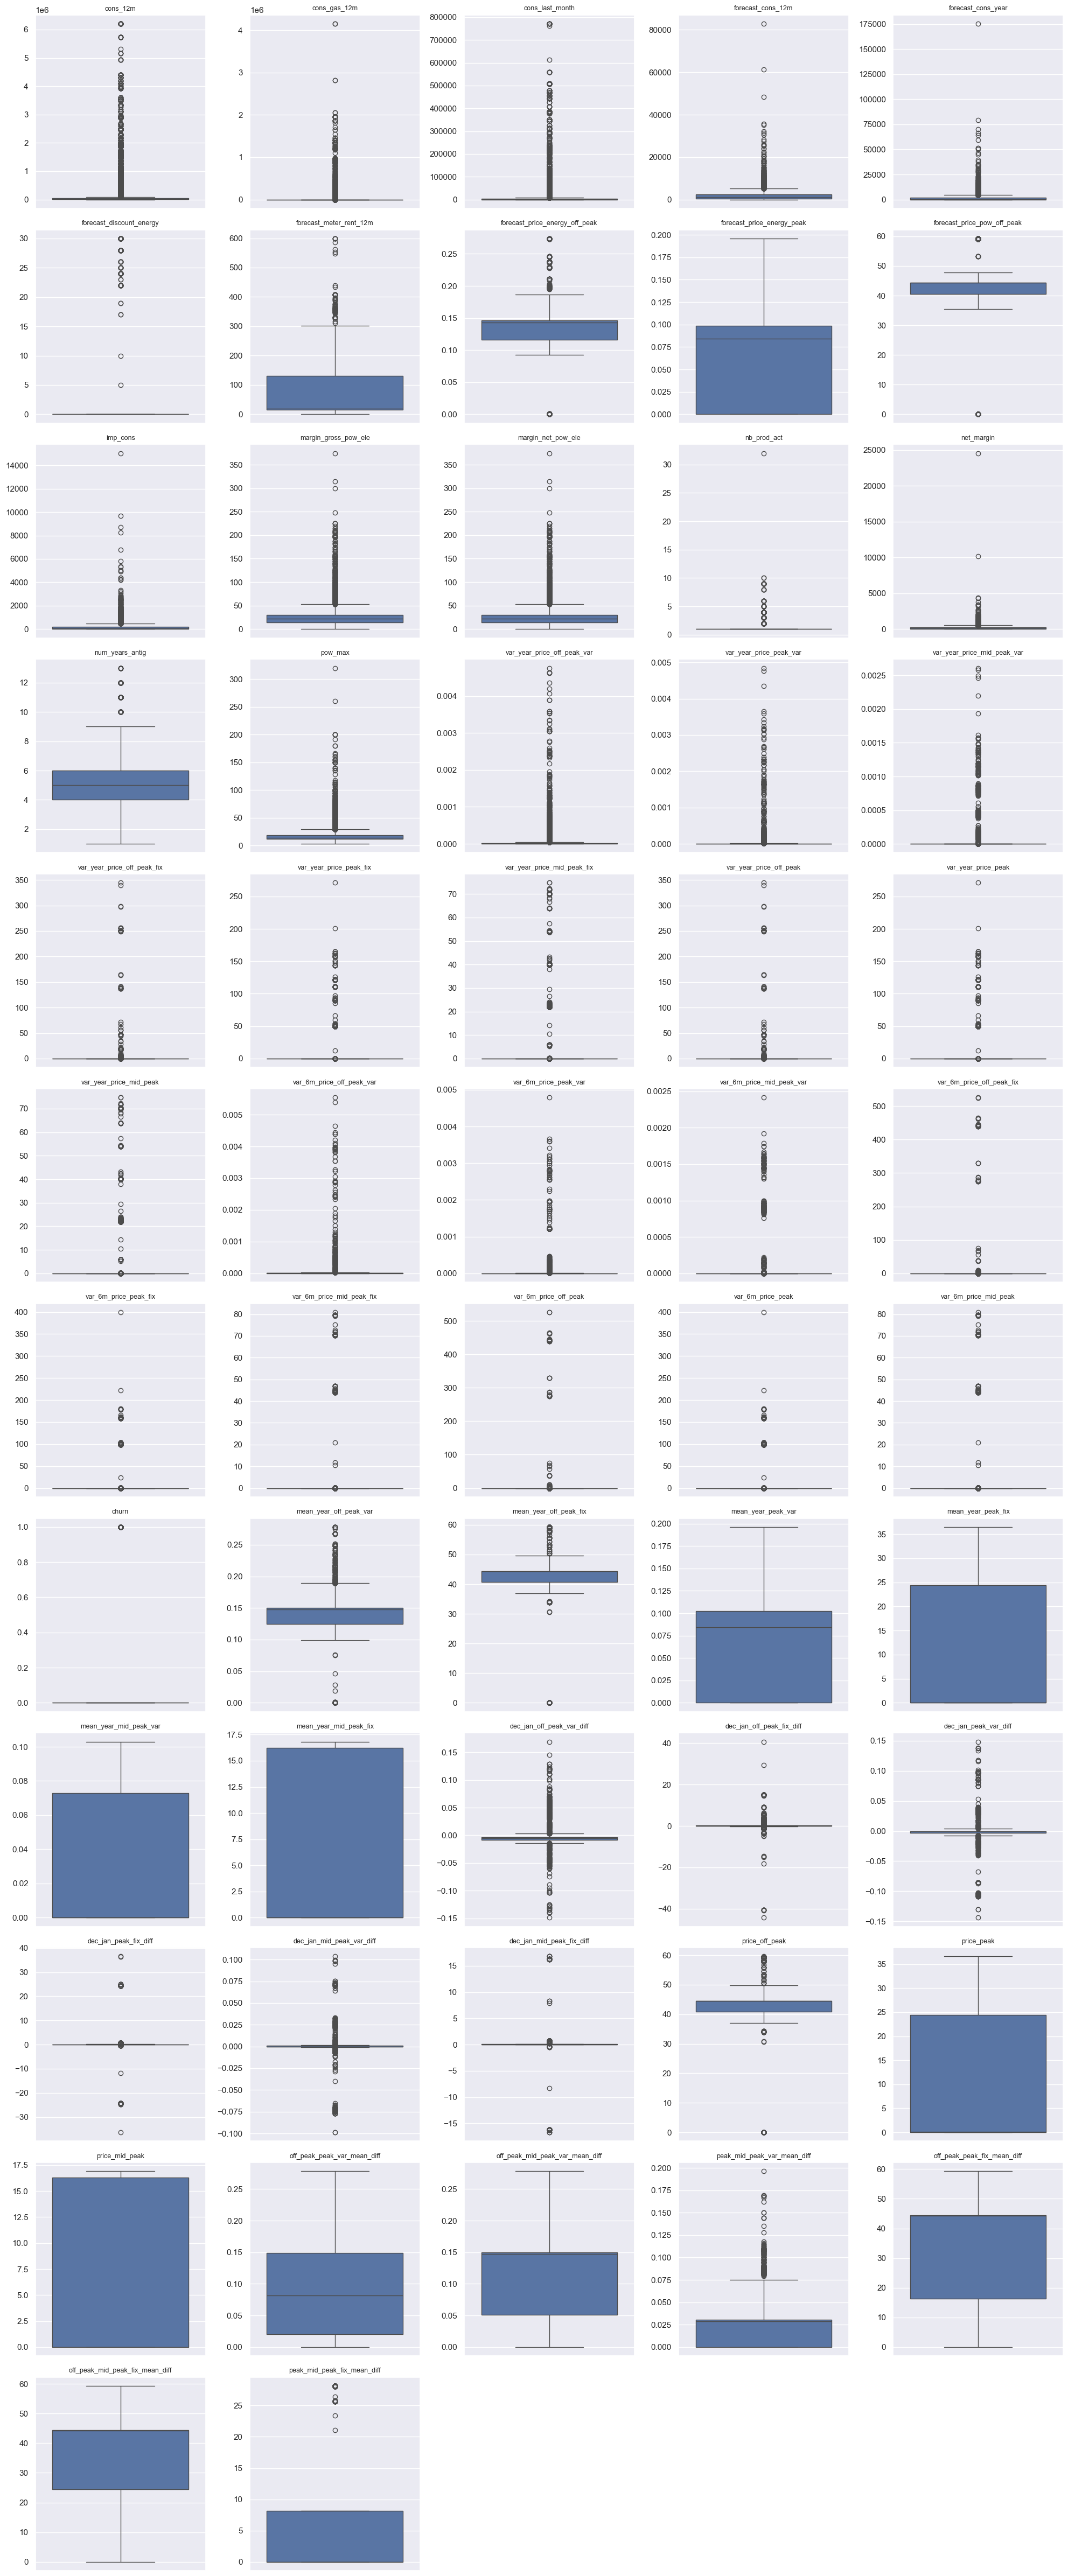

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

cols = df.drop(columns=['id']).select_dtypes(include='number').columns

n_cols = 5
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

# Hide unused subplots
for i in range(len(cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

In [35]:
zero_negative_summary = pd.DataFrame({
    'zero_count': (df.select_dtypes(include='number') == 0).sum(),
    'negative_count': (df.select_dtypes(include='number') < 0).sum(),
    'positive_count': (df.select_dtypes(include='number') > 0).sum()
})

zero_negative_summary[
    (zero_negative_summary['zero_count'] > 0) |
    (zero_negative_summary['negative_count'] > 0)
]

,zero_count,negative_count,positive_count
cons_12m,117,0,14489
cons_gas_12m,11994,0,2612
cons_last_month,4983,0,9623
forecast_cons_12m,306,0,14300
forecast_cons_year,6148,0,8458
forecast_discount_energy,14094,0,512
forecast_meter_rent_12m,725,0,13881
forecast_price_energy_off_peak,22,0,14584
forecast_price_energy_peak,7021,0,7585
forecast_price_pow_off_peak,94,0,14512


In [36]:
# Calculate customer tenure in years using activation and contract end dates
df['tenure'] = ((df['date_end'] - df['date_activ']).dt.days / 365.25).astype(int)

# Calculate churn rate for each tenure group and sort from highest to lowest
df.groupby(['tenure']).agg({'churn': 'mean'}).sort_values(by='churn', ascending=False)

,churn
tenure,
3,0.143713
2,0.133080
4,0.125756
13,0.095238
5,0.085425
12,0.083333
6,0.080713
7,0.073394
11,0.063584


**What are we doing?**

We are calculating **customer tenure in years** using the difference between `date_activ` and `date_end`.

Then, we group customers by tenure and calculate the **churn rate for each tenure group** using the mean of `churn`.

**Observation**

- Customers with **2–4 years of tenure** have relatively higher churn rates.
- Customers with **8–10 years of tenure** have lower churn rates.
- The highest churn rate is for customers with 3 years of tenure (14.37%).
- Overall, churn tends to be lower among customers with longer tenure, although the pattern is not perfectly consistent.

**Conclusion:** Customers with shorter tenure appear more likely to churn than customers with longer tenure. This is an association, not proof of causation.

## Consumption-based features

### Last-month consumption compared with average consumption

In [37]:
# Consumption features

df['cons_last_month_ratio'] = (
    df['cons_last_month'] / ((df['cons_12m'] / 12) + 1)
)

df['cons_last_month_diff'] = (
    df['cons_last_month'] - (df['cons_12m'] / 12)
)

### Forecast vs actual consumption

In [38]:
# did this because: A large difference between forecasted and actual consumption may capture unusual customer behaviour.
df['forecast_cons_diff'] = (df['forecast_cons_12m'] - df['cons_12m'])

df['forecast_cons_ratio'] = (df['forecast_cons_12m'] / (df['cons_12m'] + 1))

df['forecast_year_ratio'] = (df['forecast_cons_year'] / (df['cons_12m'] + 1))

## Financial and margin-based features

In [39]:
# Since EDA shows that margin_gross_pow_ele and margin_net_pow_ele have almost identical values for 14,604 out of 14,606 customers, they are highly redundant.

df.drop(columns=['margin_gross_pow_ele'], inplace=True)

In [40]:
#did this because: These features represent margin relative to the customer's products and subscribed power.

df['margin_per_product'] = (df['net_margin'] / (df['nb_prod_act'] + 1))

df['margin_per_power'] = (df['net_margin'] / (df['pow_max'] + 1))

## Price-based features

In [41]:
# These features capture relative differences between tariff periods rather than only their absolute prices.
df['off_peak_peak_var_ratio'] = (df['mean_year_off_peak_var'] /(df['mean_year_peak_var'] + 1e-6))

df['off_peak_mid_peak_var_ratio'] = (df['mean_year_off_peak_var'] /(df['mean_year_mid_peak_var'] + 1e-6))

df['off_peak_peak_fix_ratio'] = (df['mean_year_off_peak_fix'] /(df['mean_year_peak_fix'] + 1e-6))

## Date-based features

In [42]:
reference_date = datetime(2015, 12, 1)

def convert_months(reference_date, df, column):
    months = (
        (reference_date.year - df[column].dt.year) * 12
        + (reference_date.month - df[column].dt.month)
    )
    return months

df['months_activ'] = convert_months(reference_date, df, 'date_activ')

df['months_to_end'] = -convert_months(reference_date, df, 'date_end')

df['months_modif_prod'] = convert_months(reference_date, df, 'date_modif_prod')

df['months_renewal'] = convert_months(reference_date, df, 'date_renewal')

In [43]:
# Extract calendar month from date columns
df['activation_month'] = df['date_activ'].dt.month

df['renewal_month'] = df['date_renewal'].dt.month

df['modification_month'] = df['date_modif_prod'].dt.month

## Zero-consumption indicators

In [44]:
# Create binary indicators for zero consumption

df['zero_gas_consumption'] = (df['cons_gas_12m'] == 0).astype(int)

df['zero_last_month_consumption'] = (df['cons_last_month'] == 0).astype(int)

df['zero_forecast_consumption'] = (df['forecast_cons_year'] == 0).astype(int)

## Price trend features

In [45]:
price_df = price_df.sort_values(['id', 'price_date'])

price_trend_df = price_df.groupby('id').agg(
    first_6m_off_peak_var=('price_off_peak_var',
                           lambda x: x.iloc[:6].mean()),

    last_6m_off_peak_var=('price_off_peak_var',
                          lambda x: x.iloc[6:].mean()),

    first_6m_peak_var=('price_peak_var',
                       lambda x: x.iloc[:6].mean()),

    last_6m_peak_var=('price_peak_var',
                      lambda x: x.iloc[6:].mean())
).reset_index()

price_trend_df['off_peak_6m_change'] = (
    price_trend_df['last_6m_off_peak_var']
    - price_trend_df['first_6m_off_peak_var']
)

price_trend_df['peak_6m_change'] = (
    price_trend_df['last_6m_peak_var']
    - price_trend_df['first_6m_peak_var']
)

In [46]:
df = df.merge(
    price_trend_df,
    on='id',
    how='left'
)

In [47]:
df.shape

(14606, 91)

In [48]:
for i in df.columns:
    print(i)

id
channel_sales
cons_12m
cons_gas_12m
cons_last_month
date_activ
date_end
date_modif_prod
date_renewal
forecast_cons_12m
forecast_cons_year
forecast_discount_energy
forecast_meter_rent_12m
forecast_price_energy_off_peak
forecast_price_energy_peak
forecast_price_pow_off_peak
has_gas
imp_cons
margin_net_pow_ele
nb_prod_act
net_margin
num_years_antig
origin_up
pow_max
var_year_price_off_peak_var
var_year_price_peak_var
var_year_price_mid_peak_var
var_year_price_off_peak_fix
var_year_price_peak_fix
var_year_price_mid_peak_fix
var_year_price_off_peak
var_year_price_peak
var_year_price_mid_peak
var_6m_price_off_peak_var
var_6m_price_peak_var
var_6m_price_mid_peak_var
var_6m_price_off_peak_fix
var_6m_price_peak_fix
var_6m_price_mid_peak_fix
var_6m_price_off_peak
var_6m_price_peak
var_6m_price_mid_peak
churn
mean_year_off_peak_var
mean_year_off_peak_fix
mean_year_peak_var
mean_year_peak_fix
mean_year_mid_peak_var
mean_year_mid_peak_fix
dec_jan_off_peak_var_diff
dec_jan_off_peak_fix_diff
dec_j

In [49]:
print("Duplicate columns:", df.columns[df.columns.duplicated()].tolist())
df.drop(columns=['id']).duplicated().sum()

Duplicate columns: []


0

In [50]:
df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,modification_month,zero_gas_consumption,zero_last_month_consumption,zero_forecast_consumption,first_6m_off_peak_var,last_6m_off_peak_var,first_6m_peak_var,last_6m_peak_var,off_peak_6m_change,peak_6m_change
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,11,0,1,1,0.125976,0.123598,0.103395,0.098104,-0.002378,-0.005291
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,8,1,1,1,0.151367,0.147851,0.000000,0.014247,-0.003516,0.014247
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,4,1,1,1,0.172454,0.168569,0.088308,0.088535,-0.003885,0.000227
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,3,1,1,1,0.153090,0.149330,0.000000,0.000000,-0.003761,0.000000
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,1,1,0,0,0.127082,0.121266,0.104909,0.102368,-0.005816,-0.002541


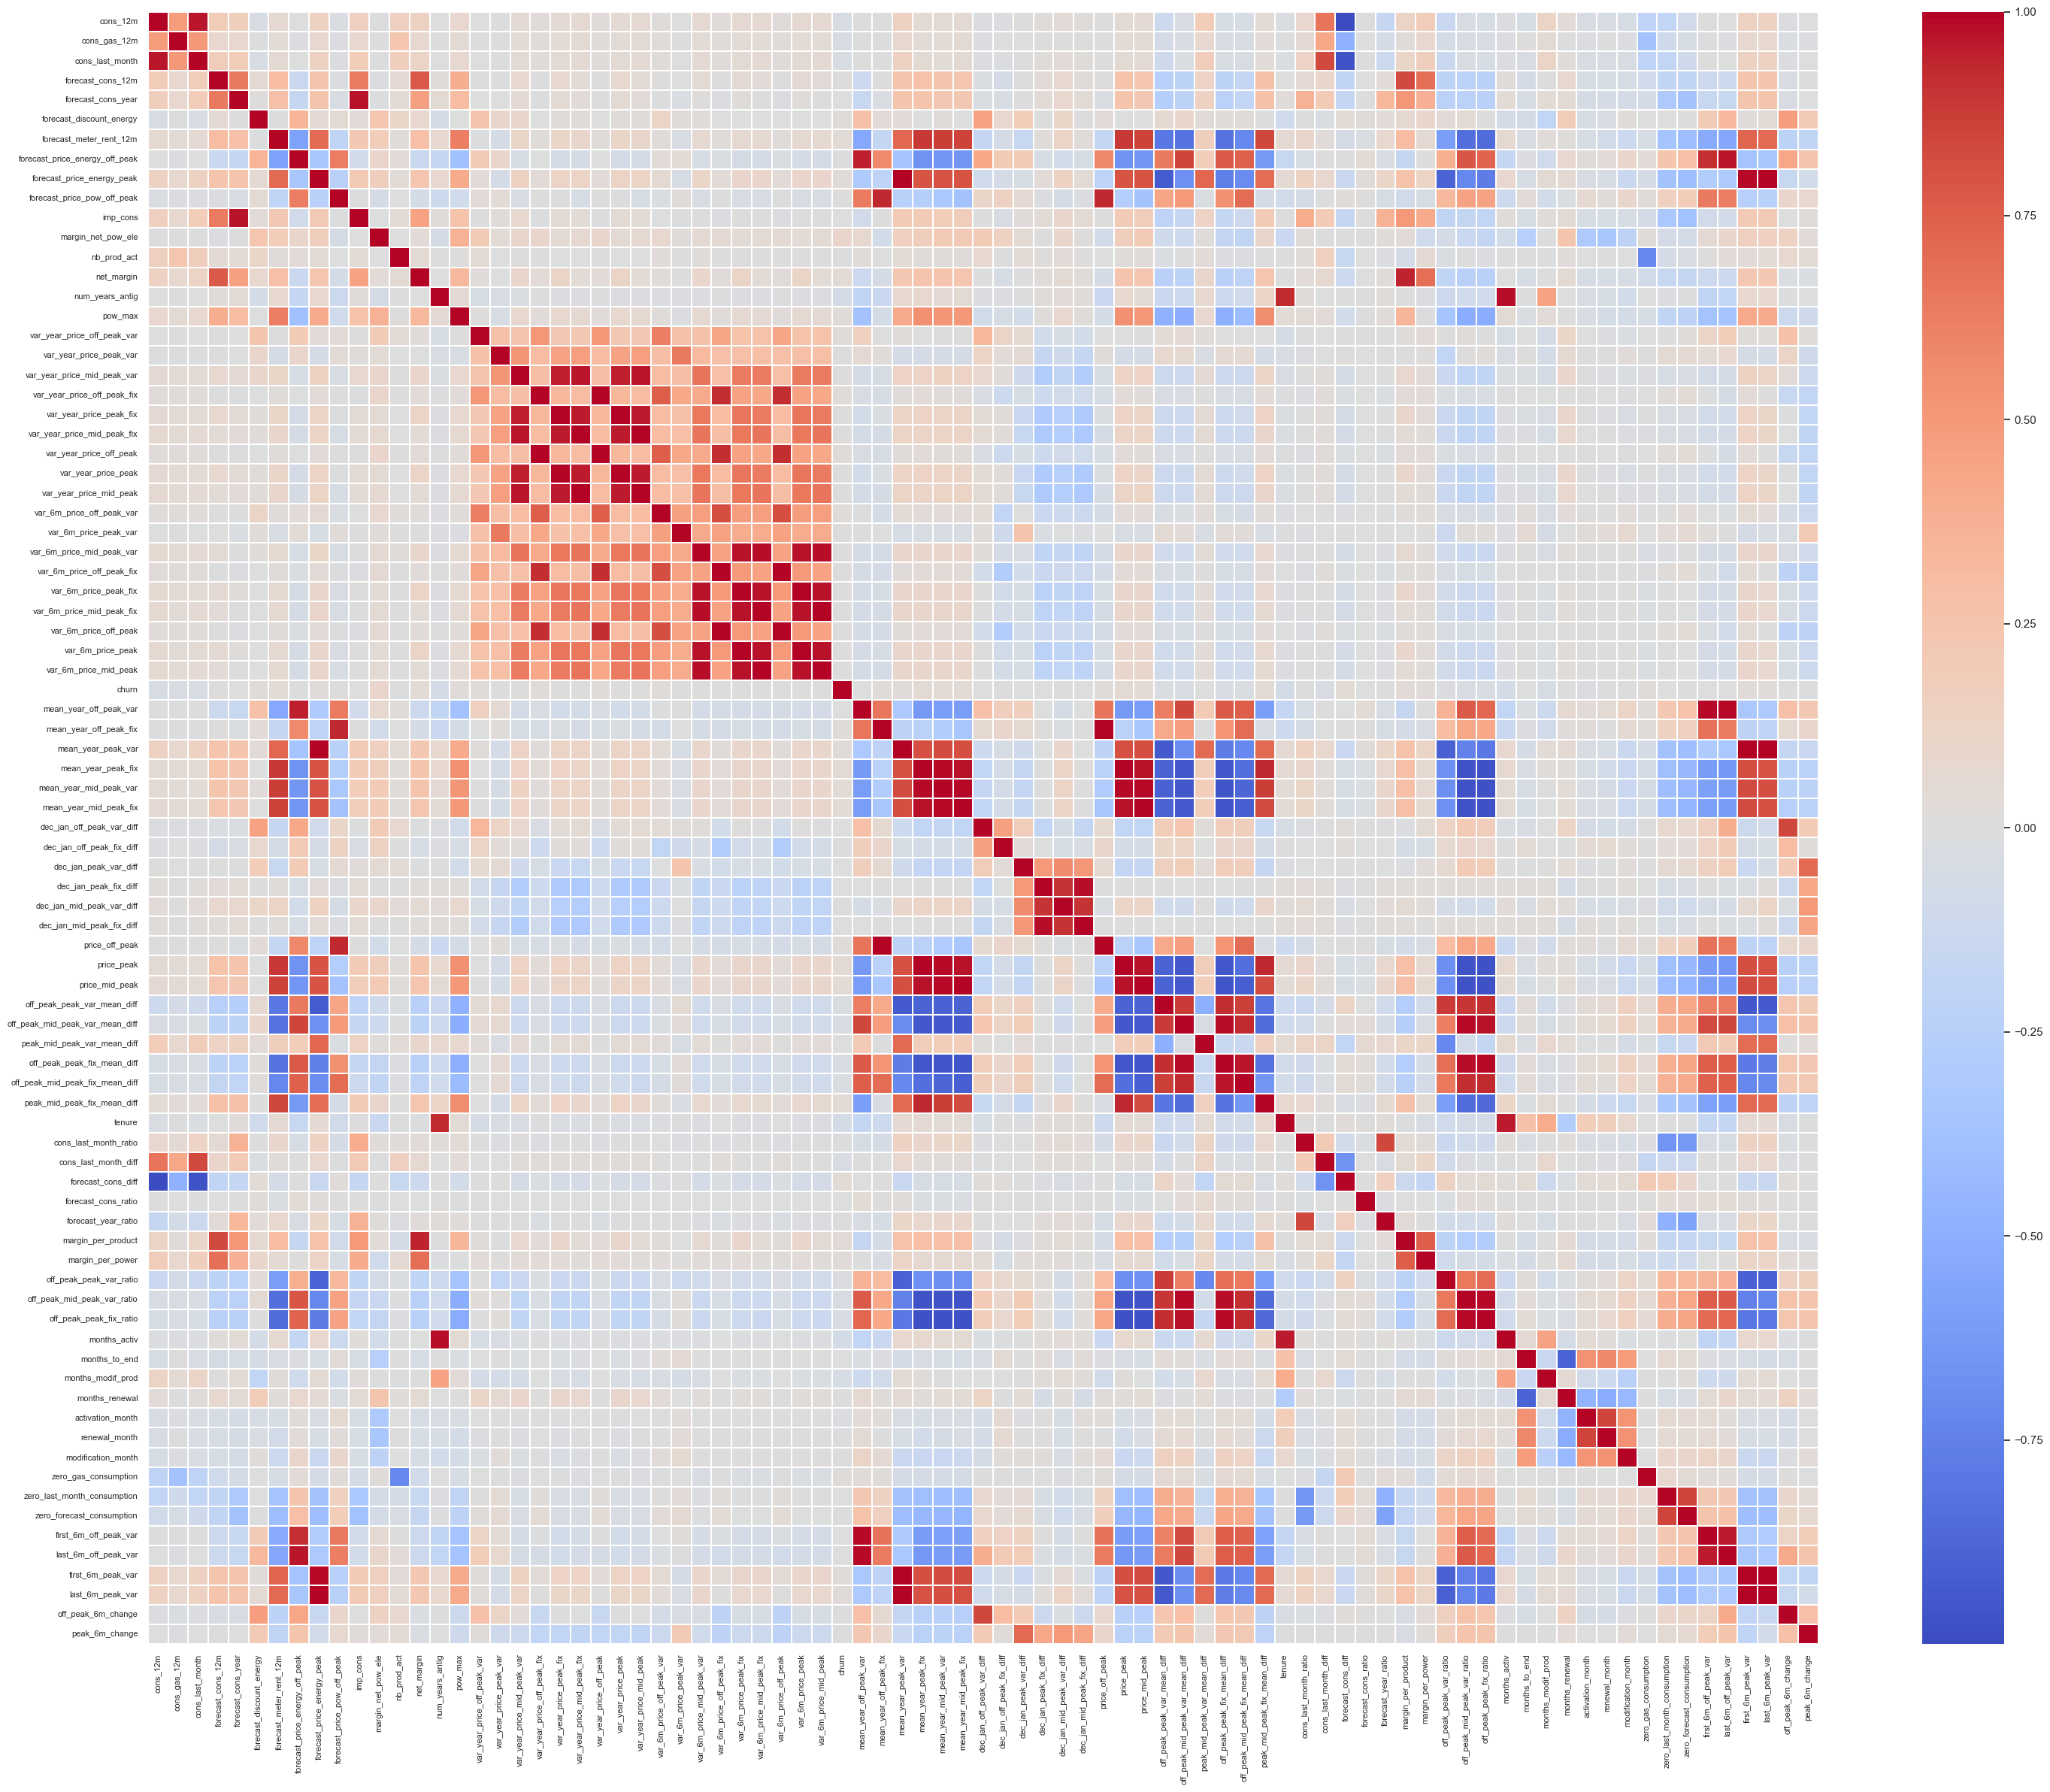

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select numerical columns
corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(30, 24))

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    linewidths=0.2,
    annot=False
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()

plt.show()

In [52]:
# Find highly correlated feature pairs

corr_features = corr.drop(index='churn', columns='churn')

upper = corr_features.where(
    np.triu(np.ones(corr_features.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']

high_corr = high_corr[
    high_corr['Correlation'].abs() > 0.85
].sort_values(
    by='Correlation',
    key=abs,
    ascending=False
)

high_corr

,Feature 1,Feature 2,Correlation
1997,var_6m_price_mid_peak_fix,var_6m_price_mid_peak,1.000000
1493,var_year_price_mid_peak_fix,var_year_price_mid_peak,1.000000
1892,var_6m_price_off_peak_fix,var_6m_price_off_peak,1.000000
1432,var_year_price_peak_fix,var_year_price_peak,1.000000
1945,var_6m_price_peak_fix,var_6m_price_peak,1.000000
1370,var_year_price_off_peak_fix,var_year_price_off_peak,1.000000
2426,mean_year_mid_peak_fix,price_mid_peak,1.000000
2340,mean_year_peak_fix,price_peak,0.999997
2250,mean_year_off_peak_fix,price_off_peak,0.999993
57,cons_12m,forecast_cons_diff,-0.999992


In [53]:
df.shape

(14606, 91)

In [54]:
null_features(df)

,Name,dtypes,Uniques,Null,Null(%),Has Null
1,activation_month,int32,12,0,0.0%,False
2,channel_sales,object,8,0,0.0%,False
3,churn,int64,2,0,0.0%,False
4,cons_12m,int64,11065,0,0.0%,False
5,cons_gas_12m,int64,2112,0,0.0%,False
6,cons_last_month,int64,4751,0,0.0%,False
7,cons_last_month_diff,float64,11861,0,0.0%,False
8,cons_last_month_ratio,float64,8210,0,0.0%,False
9,date_activ,datetime64[ns],1796,0,0.0%,False
10,date_end,datetime64[ns],368,0,0.0%,False


# Extended Feature Engineering

## FE-Part A: Price Sensitivity Features

In [55]:

import pandas as pd
import numpy as np

# ============================================================
# FE-PART A: PRICE SENSITIVITY FEATURES
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PREDICTION_CUTOFF = "2015-12-01"
EPSILON = 1e-8

PRICE_COLS = [
    "price_off_peak_var",
    "price_peak_var",
    "price_mid_peak_var",
    "price_off_peak_fix",
    "price_peak_fix",
    "price_mid_peak_fix"
]

# Preserve original dataframe
df_fe_exp1 = df.copy()

# ------------------------------------------------------------
# 2. PREPARE MONTHLY PRICE DATA
# ------------------------------------------------------------

price_exp1 = price_df.copy()

price_exp1["price_date"] = pd.to_datetime(
    price_exp1["price_date"],
    dayfirst=True,
    errors="coerce"
)

for col in PRICE_COLS:
    price_exp1[col] = pd.to_numeric(
        price_exp1[col],
        errors="coerce"
    )

price_exp1 = price_exp1.dropna(
    subset=["price_date"]
)

PREDICTION_CUTOFF = pd.to_datetime(
    PREDICTION_CUTOFF
)

price_exp1 = price_exp1[
    price_exp1["price_date"] <= PREDICTION_CUTOFF
].copy()

print("=" * 60)
print("STEP 1: PRICE DATA AFTER CUTOFF")
print("=" * 60)

print("Price data shape:", price_exp1.shape)
print(
    "Date range:",
    price_exp1["price_date"].min(),
    "to",
    price_exp1["price_date"].max()
)

# ------------------------------------------------------------
# 3. FILTER CUSTOMER IDs
# ------------------------------------------------------------

client_ids = client_clean_df["id"].unique()

price_exp1 = price_exp1[
    price_exp1["id"].isin(client_ids)
].copy()

print("\n" + "=" * 60)
print("STEP 2: CUSTOMER ID FILTERING")
print("=" * 60)

print("Filtered price data shape:", price_exp1.shape)
print("Unique customers:", price_exp1["id"].nunique())

print(
    "Client IDs missing from filtered price data:",
    len(set(client_ids) - set(price_exp1["id"].unique()))
)

# ------------------------------------------------------------
# 4. CHECK DUPLICATE CUSTOMER-MONTH RECORDS
# ------------------------------------------------------------

duplicate_count = price_exp1.duplicated(
    subset=["id", "price_date"]
).sum()

print("\nDuplicate customer-month records:", duplicate_count)

if duplicate_count > 0:
    raise ValueError("Duplicate customer-month records found!")

# ------------------------------------------------------------
# 5. CUSTOMER-LEVEL PRICE AGGREGATION
# ------------------------------------------------------------

price_stats = price_exp1.groupby("id")[PRICE_COLS].agg(
    ["mean", "std"]
)

price_stats.columns = [
    f"{col}_{stat}"
    for col, stat in price_stats.columns
]

price_stats = price_stats.reset_index()

# ------------------------------------------------------------
# 6. FEATURE GROUP 1: PRICE VOLATILITY
# ------------------------------------------------------------

VOLATILITY_FEATURES = []

for col in PRICE_COLS:

    short_name = col.replace("price_", "")

    mean_col = f"{col}_mean"
    std_col = f"{col}_std"

    new_col = f"{short_name}_cv"

    denominator = price_stats[mean_col].abs()

    price_stats[new_col] = np.where(
        denominator > EPSILON,
        price_stats[std_col] / denominator,
        np.nan
    )

    VOLATILITY_FEATURES.append(new_col)

# ------------------------------------------------------------
# 7. FEATURE GROUP 2: RELATIVE PRICE DIFFERENCES
# ------------------------------------------------------------

# Keep only relative features that are not exact duplicates
# of the existing original feature names.

def safe_relative_change(spread, baseline):

    denominator = baseline.abs()

    return np.where(
        denominator > EPSILON,
        spread / denominator,
        np.nan
    )

# Calculate spreads internally for relative features
peak_offpeak_var_spread = (
    price_stats["price_peak_var_mean"]
    - price_stats["price_off_peak_var_mean"]
)

midpeak_offpeak_var_spread = (
    price_stats["price_mid_peak_var_mean"]
    - price_stats["price_off_peak_var_mean"]
)

peak_offpeak_fix_spread = (
    price_stats["price_peak_fix_mean"]
    - price_stats["price_off_peak_fix_mean"]
)

price_stats["peak_offpeak_var_relative"] = safe_relative_change(
    peak_offpeak_var_spread,
    price_stats["price_off_peak_var_mean"]
)

price_stats["midpeak_offpeak_var_relative"] = safe_relative_change(
    midpeak_offpeak_var_spread,
    price_stats["price_off_peak_var_mean"]
)

price_stats["peak_offpeak_fix_relative"] = safe_relative_change(
    peak_offpeak_fix_spread,
    price_stats["price_off_peak_fix_mean"]
)

RELATIVE_FEATURES = [
    "peak_offpeak_var_relative",
    "midpeak_offpeak_var_relative",
    "peak_offpeak_fix_relative"
]

# ------------------------------------------------------------
# 8. SELECT FINAL FEATURES
# ------------------------------------------------------------

NEW_FEATURES_A = (
    VOLATILITY_FEATURES
    + RELATIVE_FEATURES
)

price_features = price_stats[
    ["id"] + NEW_FEATURES_A
].copy()

print("\n" + "=" * 60)
print("STEP 3: FEATURE CREATION")
print("=" * 60)

print("Total new features:", len(NEW_FEATURES_A))

for feature in NEW_FEATURES_A:
    print("-", feature)

# ------------------------------------------------------------
# 9. MERGE WITH EXISTING DATAFRAME
# ------------------------------------------------------------

if df_fe_exp1["id"].duplicated().any():
    raise ValueError("Duplicate IDs found in df!")

if price_features["id"].duplicated().any():
    raise ValueError("Duplicate IDs found in price_features!")

original_shape = df_fe_exp1.shape

df_fe_exp1 = df_fe_exp1.merge(
    price_features,
    on="id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 10. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 4: FINAL VALIDATION")
print("=" * 60)

print("\nOriginal dataframe shape:", original_shape)
print("Final dataframe shape:", df_fe_exp1.shape)

print(
    "Rows preserved:",
    original_shape[0] == df_fe_exp1.shape[0]
)

print(
    "Features added:",
    df_fe_exp1.shape[1] - original_shape[1]
)

print("Unique customer IDs:", df_fe_exp1["id"].nunique())

print("\nMissing values in new features:")
print(df_fe_exp1[NEW_FEATURES_A].isnull().sum())

print("\nFeature summary:")
print(df_fe_exp1[NEW_FEATURES_A].describe().T)

print("\nInfinite values:")
print(np.isinf(df_fe_exp1[NEW_FEATURES_A]).sum())

# ------------------------------------------------------------
# 11. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FE-EXP 1 - PART A COMPLETED")
print("=" * 60)

print("Final dataset shape:", df_fe_exp1.shape)
print("New features created:", len(NEW_FEATURES_A))

# Original df remains unchanged.
# Use df_fe_exp1 for Part B.


STEP 1: PRICE DATA AFTER CUTOFF
Price data shape: (193002, 8)
Date range: 2015-01-01 00:00:00 to 2015-12-01 00:00:00

STEP 2: CUSTOMER ID FILTERING
Filtered price data shape: (175149, 8)
Unique customers: 14606
Client IDs missing from filtered price data: 0

Duplicate customer-month records: 0

STEP 3: FEATURE CREATION
Total new features: 9
- off_peak_var_cv
- peak_var_cv
- mid_peak_var_cv
- off_peak_fix_cv
- peak_fix_cv
- mid_peak_fix_cv
- peak_offpeak_var_relative
- midpeak_offpeak_var_relative
- peak_offpeak_fix_relative

STEP 4: FINAL VALIDATION

Original dataframe shape: (14606, 91)
Final dataframe shape: (14606, 100)
Rows preserved: True
Features added: 9
Unique customer IDs: 14606

Missing values in new features:
off_peak_var_cv                   20
peak_var_cv                     6396
mid_peak_var_cv                 8947
off_peak_fix_cv                  105
peak_fix_cv                     8960
mid_peak_fix_cv                 8960
peak_offpeak_var_relative         20
midpeak_off

## FE-PART B: CONSUMPTION BEHAVIOUR FEATURES.

In [56]:

import pandas as pd
import numpy as np

# ============================================================
# FE-PART B: CONSUMPTION BEHAVIOUR FEATURES
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

EPSILON = 1e-8

# Continue from Part A
df_fe_exp1_part_b = df_fe_exp1.copy()

# Existing columns required
CONSUMPTION_COLS = [
    "cons_12m",
    "cons_last_month",
    "forecast_cons_12m",
    "pow_max",
    "cons_gas_12m"
]

# Check required columns
missing_cols = [
    col for col in CONSUMPTION_COLS
    if col not in df_fe_exp1_part_b.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

# ------------------------------------------------------------
# 2. CONVERT COLUMNS TO NUMERIC
# ------------------------------------------------------------

for col in CONSUMPTION_COLS:
    df_fe_exp1_part_b[col] = pd.to_numeric(
        df_fe_exp1_part_b[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 3. FEATURE 1: CONSUMPTION PER POWER
# ------------------------------------------------------------

# Annual electricity consumption / Maximum subscribed power

df_fe_exp1_part_b["consumption_per_power"] = (
    df_fe_exp1_part_b["cons_12m"]
    / (
        df_fe_exp1_part_b["pow_max"]
        + EPSILON
    )
)

# ------------------------------------------------------------
# 4. FEATURE 2: GAS CONSUMPTION SHARE
# ------------------------------------------------------------

# Gas consumption / (Electricity consumption + Gas consumption)

df_fe_exp1_part_b["gas_consumption_share"] = (
    df_fe_exp1_part_b["cons_gas_12m"]
    / (
        df_fe_exp1_part_b["cons_12m"]
        + df_fe_exp1_part_b["cons_gas_12m"]
        + EPSILON
    )
)

# ------------------------------------------------------------
# 5. SELECT NEW FEATURES
# ------------------------------------------------------------

NEW_FEATURES_B = [
    "consumption_per_power",
    "gas_consumption_share"
]

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FE-EXP 1 - PART B: CONSUMPTION BEHAVIOUR FEATURES")
print("=" * 60)

print("\nOriginal dataset shape:", df_fe_exp1.shape)
print("Final dataset shape:", df_fe_exp1_part_b.shape)

print("\nNew features created:", len(NEW_FEATURES_B))

for feature in NEW_FEATURES_B:
    print("-", feature)

print("\nRows preserved:",
      len(df_fe_exp1) == len(df_fe_exp1_part_b))

print("Unique IDs:", df_fe_exp1_part_b["id"].nunique())

print("Duplicate IDs:",
      df_fe_exp1_part_b["id"].duplicated().sum())

print("\nMissing values in new features:")
print(df_fe_exp1_part_b[NEW_FEATURES_B].isnull().sum())

print("\nFeature summary:")
print(df_fe_exp1_part_b[NEW_FEATURES_B].describe().T)

# ------------------------------------------------------------
# 7. CHECK INFINITE VALUES
# ------------------------------------------------------------

print("\nInfinite values in new features:")

print(
    np.isinf(
        df_fe_exp1_part_b[NEW_FEATURES_B]
    ).sum()
)

# ------------------------------------------------------------
# 8. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FE-EXP 1 - PART B COMPLETED")
print("=" * 60)

print("Final dataset shape:", df_fe_exp1_part_b.shape)
print("New features added:", len(NEW_FEATURES_B))

# Original df and df_fe_exp1 remain unchanged.
# Use df_fe_exp1_part_b for Part C.



FE-EXP 1 - PART B: CONSUMPTION BEHAVIOUR FEATURES

Original dataset shape: (14606, 100)
Final dataset shape: (14606, 102)

New features created: 2
- consumption_per_power
- gas_consumption_share

Rows preserved: True
Unique IDs: 14606
Duplicate IDs: 0

Missing values in new features:
consumption_per_power    0
gas_consumption_share    0
dtype: int64

Feature summary:
                         count         mean           std  min         25%  \
consumption_per_power  14606.0  9772.643503  37574.645616  0.0  401.557451   
gas_consumption_share  14606.0     0.079499      0.212446  0.0    0.000000   

                              50%          75%            max  
consumption_per_power  895.484507  2165.127019  590028.896778  
gas_consumption_share    0.000000     0.000000       1.000000  

Infinite values in new features:
consumption_per_power    0
gas_consumption_share    0
dtype: int64

FE-EXP 1 - PART B COMPLETED
Final dataset shape: (14606, 102)
New features added: 2


## FE-PART C: CUSTOMER PROFITABILITY AND BUSINESS VALUE.

In [57]:

import pandas as pd
import numpy as np

# ============================================================
# FE-PART C: CUSTOMER PROFITABILITY AND BUSINESS VALUE
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

# Continue from Part B
df_fe_exp1_part_c = df_fe_exp1_part_b.copy()

# Required existing columns
PROFITABILITY_COLS = [
    "net_margin",
    "cons_12m",
    "nb_prod_act",
    "tenure"
]

# Check required columns
missing_cols = [
    col for col in PROFITABILITY_COLS
    if col not in df_fe_exp1_part_c.columns
]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# ------------------------------------------------------------
# 2. CONVERT REQUIRED COLUMNS TO NUMERIC
# ------------------------------------------------------------

for col in PROFITABILITY_COLS:
    df_fe_exp1_part_c[col] = pd.to_numeric(
        df_fe_exp1_part_c[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 3. FEATURE 1: MARGIN PER CONSUMPTION
# ------------------------------------------------------------

# Net margin / Annual consumption
# Undefined when annual consumption is zero or negative.

df_fe_exp1_part_c["margin_per_consumption"] = np.where(
    df_fe_exp1_part_c["cons_12m"] > 0,
    df_fe_exp1_part_c["net_margin"]
    / df_fe_exp1_part_c["cons_12m"],
    np.nan
)

# ------------------------------------------------------------
# 4. FEATURE 2: CUSTOMER VALUE PROXY
# ------------------------------------------------------------

# Net margin * Customer tenure
# Rough business-value proxy, not actual Customer Lifetime Value.

df_fe_exp1_part_c["customer_value_proxy"] = (
    df_fe_exp1_part_c["net_margin"]
    * df_fe_exp1_part_c["tenure"]
)

# ------------------------------------------------------------
# 5. FEATURE 3: PRODUCT ADOPTION RATE
# ------------------------------------------------------------

# Active products / Customer tenure
# Undefined when tenure is zero or negative.

df_fe_exp1_part_c["product_adoption_rate"] = np.where(
    df_fe_exp1_part_c["tenure"] > 0,
    df_fe_exp1_part_c["nb_prod_act"]
    / df_fe_exp1_part_c["tenure"],
    np.nan
)

# ------------------------------------------------------------
# 6. CHECK EXISTING MARGIN PER PRODUCT FEATURE
# ------------------------------------------------------------

# Do not create a duplicate feature.

if "margin_per_product" in df_fe_exp1_part_c.columns:

    print("\nExisting feature found: margin_per_product")
    print("No duplicate feature created.")

else:

    print("\nWARNING: margin_per_product not found.")
    print("Check its existing column name before proceeding.")

# ------------------------------------------------------------
# 7. SELECT NEW FEATURES
# ------------------------------------------------------------

NEW_FEATURES_C = [
    "margin_per_consumption",
    "customer_value_proxy",
    "product_adoption_rate"
]

# ------------------------------------------------------------
# 8. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FE-EXP 1 - PART C: CUSTOMER PROFITABILITY AND BUSINESS VALUE")
print("=" * 60)

print("\nOriginal dataset shape:", df_fe_exp1_part_b.shape)
print("Final dataset shape:", df_fe_exp1_part_c.shape)

print("\nNew features created:", len(NEW_FEATURES_C))

for feature in NEW_FEATURES_C:
    print("-", feature)

print(
    "\nRows preserved:",
    len(df_fe_exp1_part_b) == len(df_fe_exp1_part_c)
)

print("Unique IDs:", df_fe_exp1_part_c["id"].nunique())

# Check duplicate IDs
print(
    "Duplicate IDs:",
    df_fe_exp1_part_c["id"].duplicated().sum()
)

# ------------------------------------------------------------
# 9. MISSING VALUE CHECK
# ------------------------------------------------------------

print("\nMissing values in new features:")

print(
    df_fe_exp1_part_c[NEW_FEATURES_C].isnull().sum()
)

# ------------------------------------------------------------
# 10. FEATURE SUMMARY
# ------------------------------------------------------------

print("\nFeature summary:")

print(
    df_fe_exp1_part_c[NEW_FEATURES_C].describe().T
)

# ------------------------------------------------------------
# 11. INFINITE VALUE CHECK
# ------------------------------------------------------------

print("\nInfinite values in new features:")

print(
    np.isinf(
        df_fe_exp1_part_c[NEW_FEATURES_C]
    ).sum()
)

# ------------------------------------------------------------
# 12. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FE-EXP 1 - PART C COMPLETED")
print("=" * 60)

print("Final dataset shape:", df_fe_exp1_part_c.shape)
print("New features added:", len(NEW_FEATURES_C))

# Original df, Part A and Part B remain unchanged.
# Use df_fe_exp1_part_c for the next feature-engineering part.



Existing feature found: margin_per_product
No duplicate feature created.

FE-EXP 1 - PART C: CUSTOMER PROFITABILITY AND BUSINESS VALUE

Original dataset shape: (14606, 102)
Final dataset shape: (14606, 105)

New features created: 3
- margin_per_consumption
- customer_value_proxy
- product_adoption_rate

Rows preserved: True
Unique IDs: 14606
Duplicate IDs: 0

Missing values in new features:
margin_per_consumption    117
customer_value_proxy        0
product_adoption_rate       0
dtype: int64

Feature summary:
                          count        mean          std       min  \
margin_per_consumption  14489.0    0.010713     0.064233  0.000000   
customer_value_proxy    14606.0  998.410308  1545.112469  0.000000   
product_adoption_rate   14606.0    0.268813     0.175178  0.076923   

                               25%        50%          75%           max  
margin_per_consumption    0.004672    0.01092     0.013165      7.443333  
customer_value_proxy    252.000000  570.95500  1206.4

Dataset Shape: (14606, 105)
Unique Customers: 14606

Numerical Dataset Shape: (14606, 97)

========== PEARSON CORRELATION WITH CHURN ==========


,pearson_corr,abs_corr
margin_net_pow_ele,0.095772,0.095772
months_activ,-0.074591,0.074591
num_years_antig,-0.074140,0.074140
tenure,-0.072409,0.072409
months_modif_prod,-0.051951,0.051951
mean_year_peak_fix,0.047240,0.047240
price_peak,0.047204,0.047204
mean_year_mid_peak_var,0.046544,0.046544
forecast_cons_diff,0.046059,0.046059
midpeak_offpeak_var_relative,0.045973,0.045973



========== SPEARMAN CORRELATION WITH CHURN ==========


,spearman_corr,abs_corr
margin_net_pow_ele,0.102541,0.102541
num_years_antig,-0.085464,0.085464
months_activ,-0.083327,0.083327
tenure,-0.081797,0.081797
off_peak_var_cv,0.051582,0.051582
var_year_price_off_peak_var,0.051154,0.051154
mean_year_mid_peak_var,0.047621,0.047621
var_year_price_mid_peak_var,0.047228,0.047228
months_modif_prod,-0.046422,0.046422
var_6m_price_off_peak_var,0.045984,0.045984



========== COMBINED TARGET CORRELATION ==========


,pearson_corr,abs_corr,spearman_corr
margin_net_pow_ele,0.095772,0.095772,0.102541
months_activ,-0.074591,0.074591,-0.083327
num_years_antig,-0.074140,0.074140,-0.085464
tenure,-0.072409,0.072409,-0.081797
months_modif_prod,-0.051951,0.051951,-0.046422
mean_year_peak_fix,0.047240,0.047240,0.044708
price_peak,0.047204,0.047204,0.036307
mean_year_mid_peak_var,0.046544,0.046544,0.047621
forecast_cons_diff,0.046059,0.046059,0.002681
midpeak_offpeak_var_relative,0.045973,0.045973,0.044891


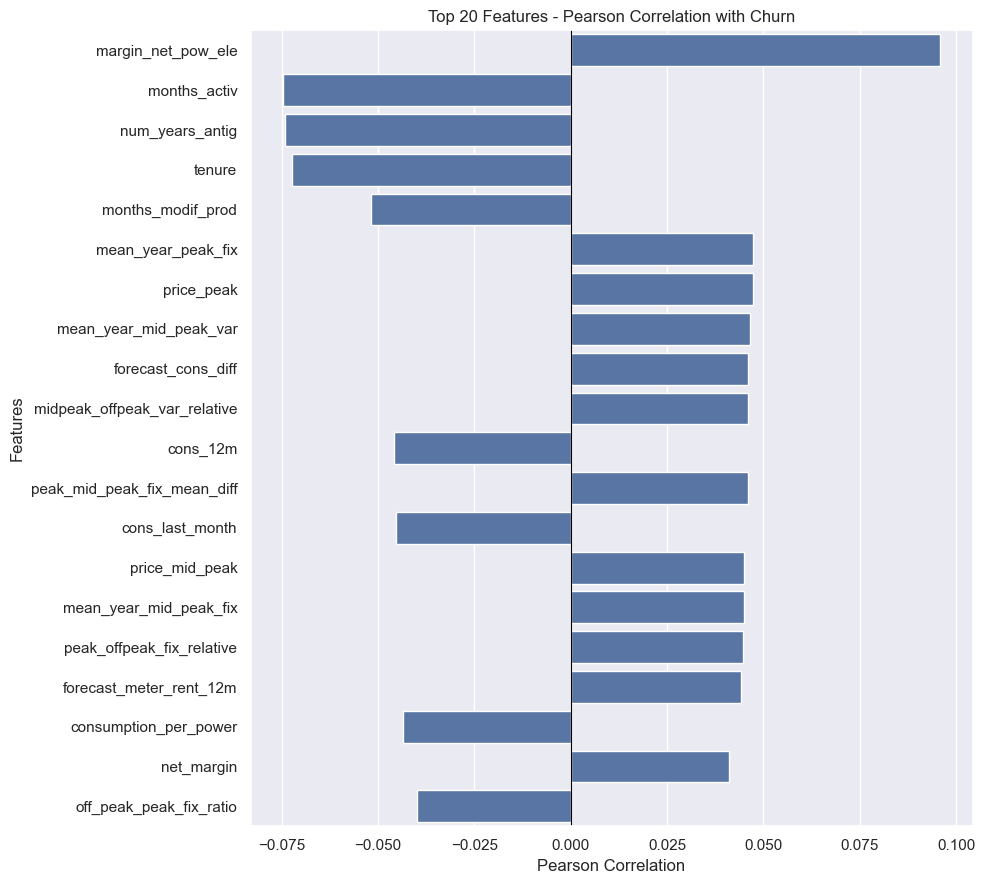


========== HIGHLY CORRELATED FEATURE PAIRS (>= 0.90) ==========


,Feature_1,Feature_2,Correlation,Abs_Correlation
2417,var_6m_price_mid_peak_fix,var_6m_price_mid_peak,1.000000,1.000000
1787,var_year_price_mid_peak_fix,var_year_price_mid_peak,1.000000,1.000000
2284,var_6m_price_off_peak_fix,var_6m_price_off_peak,1.000000,1.000000
1712,var_year_price_peak_fix,var_year_price_peak,1.000000,1.000000
2351,var_6m_price_peak_fix,var_6m_price_peak,1.000000,1.000000
1636,var_year_price_off_peak_fix,var_year_price_off_peak,1.000000,1.000000
2972,mean_year_mid_peak_fix,price_mid_peak,1.000000,1.000000
2858,mean_year_peak_fix,price_peak,0.999997,0.999997
2740,mean_year_off_peak_fix,price_off_peak,0.999993,0.999993
57,cons_12m,forecast_cons_diff,-0.999992,0.999992


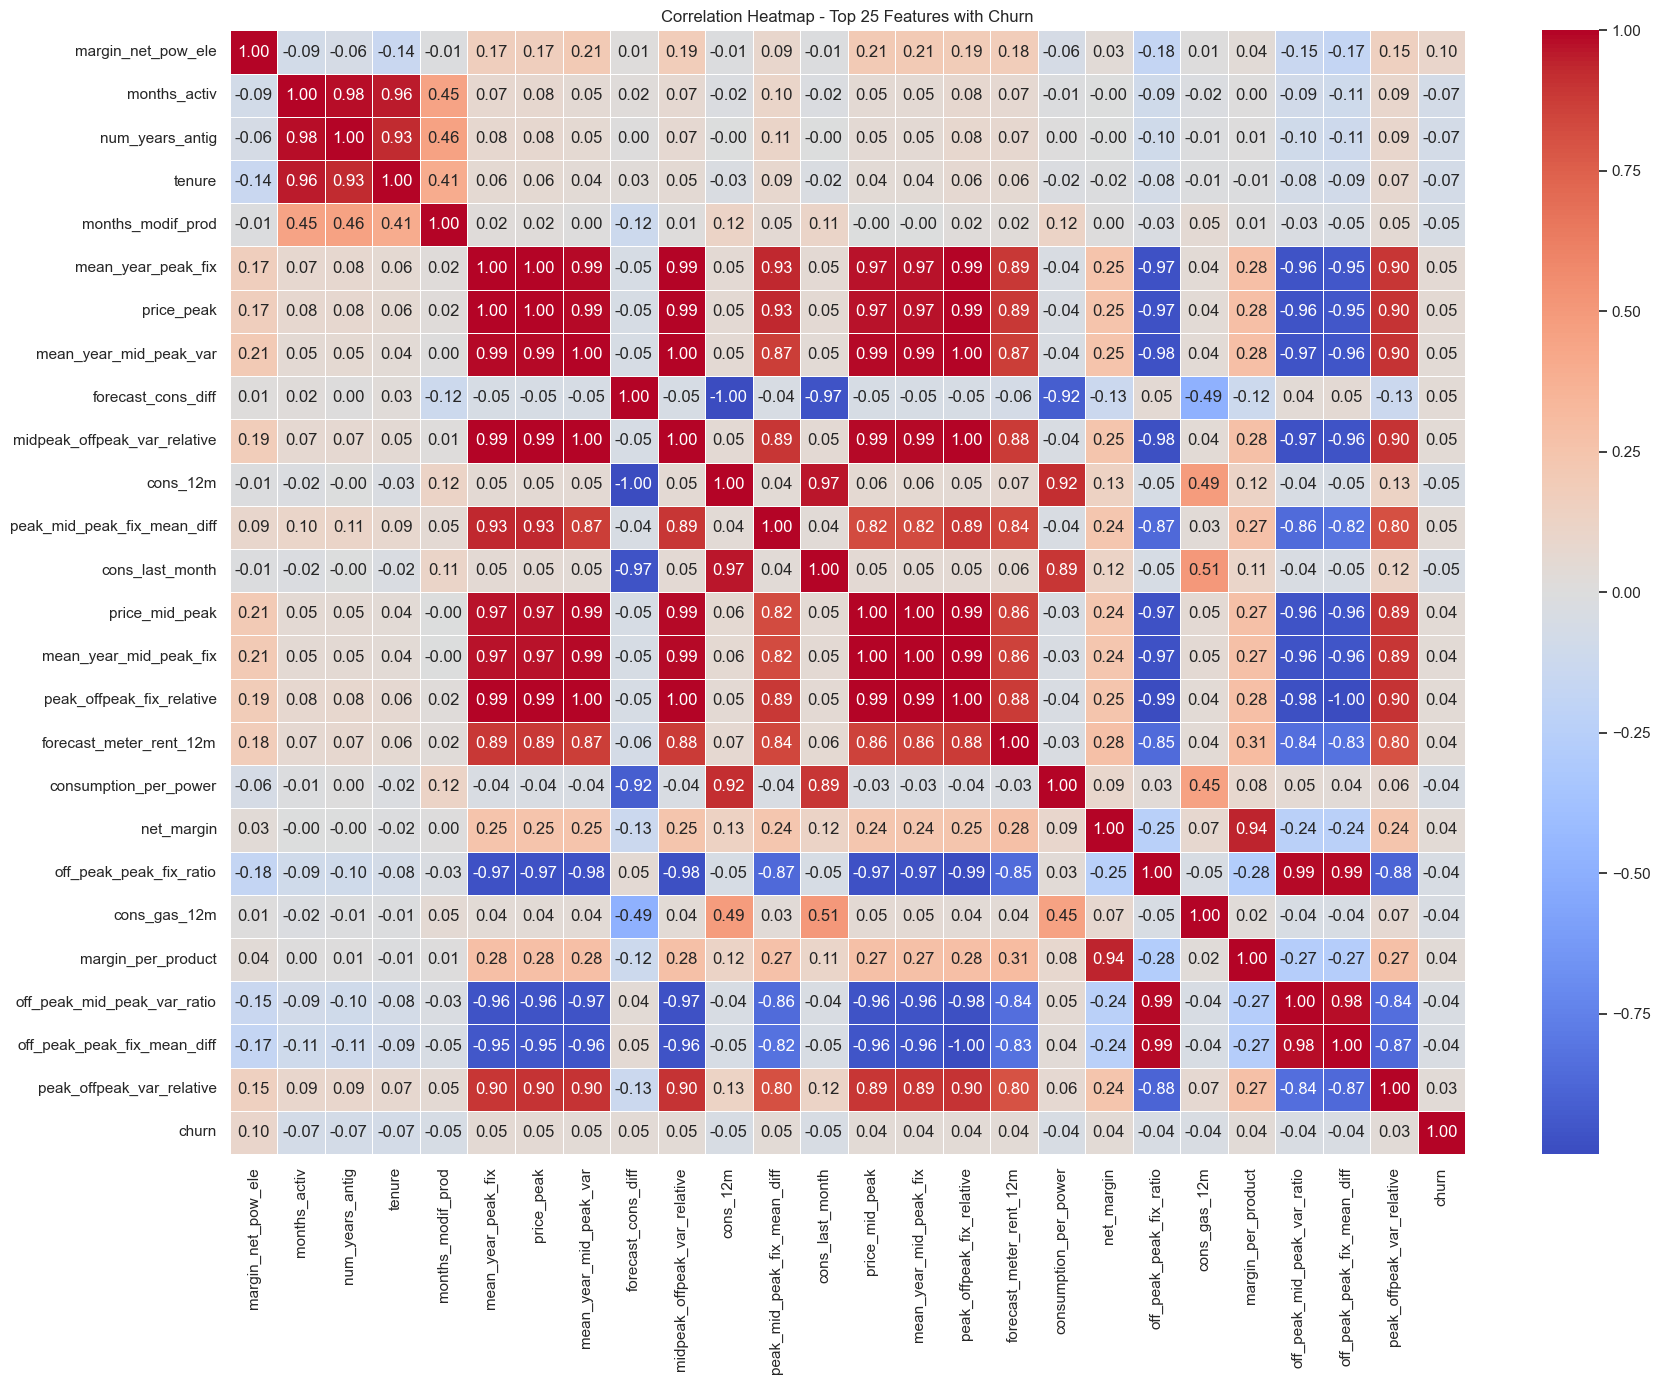

In [58]:

# ============================================================
# CORRELATION ANALYSIS - FE-EXP 1
# Dataset: df_fe_exp1_part_c
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. CREATE A COPY
# ------------------------------------------------------------

corr_df = df_fe_exp1_part_c.copy()

print("Dataset Shape:", corr_df.shape)
print("Unique Customers:", corr_df["id"].nunique())

# ------------------------------------------------------------
# 2. SELECT NUMERICAL FEATURES
# ------------------------------------------------------------

numeric_df = corr_df.select_dtypes(include=np.number).drop(
    columns=["id"],
    errors="ignore"
)

print("\nNumerical Dataset Shape:", numeric_df.shape)

# ------------------------------------------------------------
# 3. PEARSON CORRELATION WITH TARGET
# ------------------------------------------------------------

pearson_corr = numeric_df.corr(method="pearson")

target_corr = (
    pearson_corr["churn"]
    .drop("churn")
    .to_frame(name="pearson_corr")
)

target_corr["abs_corr"] = target_corr["pearson_corr"].abs()

target_corr = target_corr.sort_values(
    by="abs_corr",
    ascending=False
)

print("\n========== PEARSON CORRELATION WITH CHURN ==========")
display(target_corr)

# ------------------------------------------------------------
# 4. SPEARMAN CORRELATION WITH TARGET
# ------------------------------------------------------------

spearman_corr = numeric_df.corr(method="spearman")

spearman_target_corr = (
    spearman_corr["churn"]
    .drop("churn")
    .to_frame(name="spearman_corr")
)

spearman_target_corr["abs_corr"] = (
    spearman_target_corr["spearman_corr"].abs()
)

spearman_target_corr = spearman_target_corr.sort_values(
    by="abs_corr",
    ascending=False
)

print("\n========== SPEARMAN CORRELATION WITH CHURN ==========")
display(spearman_target_corr)

# ------------------------------------------------------------
# 5. COMBINE PEARSON AND SPEARMAN RESULTS
# ------------------------------------------------------------

target_corr_summary = target_corr.join(
    spearman_target_corr[["spearman_corr"]]
)

print("\n========== COMBINED TARGET CORRELATION ==========")
display(target_corr_summary)

# ------------------------------------------------------------
# 6. TOP 20 FEATURES CORRELATED WITH CHURN
# ------------------------------------------------------------

top_features = target_corr.head(20).index.tolist()

plt.figure(figsize=(10, 9))

sns.barplot(
    data=target_corr.head(20).reset_index(),
    x="pearson_corr",
    y="index"
)

plt.title("Top 20 Features - Pearson Correlation with Churn")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. FEATURE-TO-FEATURE CORRELATION
# ------------------------------------------------------------

feature_corr = numeric_df.drop(
    columns=["churn"]
).corr(method="pearson")

# Extract only upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

high_corr_pairs["Abs_Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Abs_Correlation"] >= 0.90
].sort_values(
    by="Abs_Correlation",
    ascending=False
)

print("\n========== HIGHLY CORRELATED FEATURE PAIRS (>= 0.90) ==========")
display(high_corr_pairs)

# ------------------------------------------------------------
# 8. HEATMAP - TOP 25 FEATURES WITH CHURN
# ------------------------------------------------------------

top_25_features = target_corr.head(25).index.tolist()

heatmap_features = top_25_features + ["churn"]

plt.figure(figsize=(18, 14))

sns.heatmap(
    numeric_df[heatmap_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap - Top 25 Features with Churn")
plt.tight_layout()
plt.show()


In [59]:
df = df_fe_exp1_part_c.copy()

print("Final dataframe shape:", df.shape)
print("Unique customers:", df["id"].nunique())
print("Duplicate IDs:", df["id"].duplicated().sum())

Final dataframe shape: (14606, 105)
Unique customers: 14606
Duplicate IDs: 0


## FE-PART D: CUSTOMER INTERACTION FEATURES

In [60]:

import pandas as pd
import numpy as np

# ============================================================
# FE-PART D: CUSTOMER INTERACTION FEATURES
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

df_before_part_e = df.copy()

df_fe_exp1_part_e = df_before_part_e.copy()

REQUIRED_COLS = [
    "first_6m_off_peak_var",
    "first_6m_peak_var",
    "off_peak_6m_change",
    "peak_6m_change",
    "cons_12m",
    "gas_consumption_share",
    "nb_prod_act",
    "tenure",
    "net_margin",
    "pow_max",
    "forecast_discount_energy"
]

missing_cols = [
    col for col in REQUIRED_COLS
    if col not in df_fe_exp1_part_e.columns
]

if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

for col in REQUIRED_COLS:
    df_fe_exp1_part_e[col] = pd.to_numeric(
        df_fe_exp1_part_e[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 2. SAFE DIVISION
# ------------------------------------------------------------

def safe_divide(numerator, denominator):

    result = pd.Series(
        np.nan,
        index=numerator.index,
        dtype="float64"
    )

    valid = (
        numerator.notna()
        & denominator.notna()
        & (denominator.abs() > 0)
    )

    result.loc[valid] = (
        numerator.loc[valid] / denominator.loc[valid]
    )

    return result

# ------------------------------------------------------------
# 3. RELATIVE PRICE CHANGE WITH BASELINE FILTER
# ------------------------------------------------------------

# Calculate the 1st percentile using positive baseline values only.

off_peak_positive = df_fe_exp1_part_e.loc[
    df_fe_exp1_part_e["first_6m_off_peak_var"] > 0,
    "first_6m_off_peak_var"
]

peak_positive = df_fe_exp1_part_e.loc[
    df_fe_exp1_part_e["first_6m_peak_var"] > 0,
    "first_6m_peak_var"
]

off_peak_min_baseline = off_peak_positive.quantile(0.01)

peak_min_baseline = peak_positive.quantile(0.01)

print("Off-peak minimum baseline:", off_peak_min_baseline)
print("Peak minimum baseline:", peak_min_baseline)

# Off-peak relative price change

off_peak_baseline = df_fe_exp1_part_e[
    "first_6m_off_peak_var"
].where(
    df_fe_exp1_part_e["first_6m_off_peak_var"]
    >= off_peak_min_baseline
)

off_peak_relative_change = safe_divide(
    df_fe_exp1_part_e["off_peak_6m_change"],
    off_peak_baseline
)

# Peak relative price change

peak_baseline = df_fe_exp1_part_e[
    "first_6m_peak_var"
].where(
    df_fe_exp1_part_e["first_6m_peak_var"]
    >= peak_min_baseline
)

peak_relative_change = safe_divide(
    df_fe_exp1_part_e["peak_6m_change"],
    peak_baseline
)

# Average available tariff-specific changes.
# If one tariff is unavailable, use the other.
# If both are unavailable, result remains NaN.

relative_price_change = pd.concat(
    [
        off_peak_relative_change,
        peak_relative_change
    ],
    axis=1
).mean(axis=1)

# ------------------------------------------------------------
# 4. FEATURE 1: PRICE CONSUMPTION EXPOSURE
# ------------------------------------------------------------

df_fe_exp1_part_e["price_consumption_exposure"] = (
    relative_price_change
    * df_fe_exp1_part_e["cons_12m"]
)

# ------------------------------------------------------------
# 5. FEATURE 2: GAS PRODUCT INTERACTION
# ------------------------------------------------------------

df_fe_exp1_part_e["gas_product_interaction"] = (
    df_fe_exp1_part_e["gas_consumption_share"]
    * df_fe_exp1_part_e["nb_prod_act"]
)

# ------------------------------------------------------------
# 6. FEATURE 3: TENURE MARGIN INTERACTION
# ------------------------------------------------------------

df_fe_exp1_part_e["tenure_margin_interaction"] = (
    df_fe_exp1_part_e["tenure"]
    * df_fe_exp1_part_e["net_margin"]
)

# ------------------------------------------------------------
# 7. FEATURE 4: PRICE POWER INTERACTION
# ------------------------------------------------------------

df_fe_exp1_part_e["price_power_interaction"] = (
    relative_price_change
    * df_fe_exp1_part_e["pow_max"]
)

# ------------------------------------------------------------
# 8. FEATURE 5: DISCOUNT CONSUMPTION INTERACTION
# ------------------------------------------------------------

df_fe_exp1_part_e["discount_consumption_interaction"] = (
    df_fe_exp1_part_e["forecast_discount_energy"]
    * df_fe_exp1_part_e["cons_12m"]
)

# ------------------------------------------------------------
# 9. SELECT NEW FEATURES
# ------------------------------------------------------------

NEW_FEATURES_E = [
    "price_consumption_exposure",
    "gas_product_interaction",
    "tenure_margin_interaction",
    "price_power_interaction",
    "discount_consumption_interaction"
]

# ------------------------------------------------------------
# 10. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FE-EXP 1 - PART E: CUSTOMER INTERACTION FEATURES")
print("=" * 65)

print("\nOriginal dataset shape:", df_before_part_e.shape)
print("Final dataset shape:", df_fe_exp1_part_e.shape)

print("\nNew features created:", len(NEW_FEATURES_E))

for feature in NEW_FEATURES_E:
    print("-", feature)

print("\nRows preserved:",
      len(df_before_part_e) == len(df_fe_exp1_part_e))

print("Unique customers:",
      df_fe_exp1_part_e["id"].nunique())

print("Duplicate IDs:",
      df_fe_exp1_part_e["id"].duplicated().sum())

print("\nMissing values:")

print(
    df_fe_exp1_part_e[NEW_FEATURES_E].isnull().sum()
)

print("\nFeature summary:")

print(
    df_fe_exp1_part_e[NEW_FEATURES_E].describe().T
)

print("\nInfinite values:")

print(
    np.isinf(
        df_fe_exp1_part_e[NEW_FEATURES_E]
    ).sum()
)

# ------------------------------------------------------------
# 11. RELATIVE PRICE CHANGE VALIDATION
# ------------------------------------------------------------

print("\nRelative price change summary:")

print(relative_price_change.describe())

print("\nAvailable off-peak observations:",
      off_peak_relative_change.notna().sum())

print("Available peak observations:",
      peak_relative_change.notna().sum())

print("Available combined observations:",
      relative_price_change.notna().sum())

# ------------------------------------------------------------
# 12. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FE-EXP 1 - PART E COMPLETED")
print("=" * 65)

print("Final dataset shape:", df_fe_exp1_part_e.shape)

print("New features added:", len(NEW_FEATURES_E))

# Update working dataframe
df = df_fe_exp1_part_e.copy()

print("\nWorking dataframe updated.")
print("df shape:", df.shape)

# Original pre-Part-E dataframe remains available:
# df_before_part_e


Off-peak minimum baseline: 0.10645899999999998
Peak minimum baseline: 0.014247166666666667

FE-EXP 1 - PART E: CUSTOMER INTERACTION FEATURES

Original dataset shape: (14606, 105)
Final dataset shape: (14606, 110)

New features created: 5
- price_consumption_exposure
- gas_product_interaction
- tenure_margin_interaction
- price_power_interaction
- discount_consumption_interaction

Rows preserved: True
Unique customers: 14606
Duplicate IDs: 0

Missing values:
price_consumption_exposure          107
gas_product_interaction               0
tenure_margin_interaction             0
price_power_interaction             107
discount_consumption_interaction      0
dtype: int64

Feature summary:
                                    count          mean            std  \
price_consumption_exposure        14499.0  -4717.595766   36271.542058   
gas_product_interaction           14606.0      0.188425       0.527522   
tenure_margin_interaction         14606.0    998.410308    1545.112469   
price_power

In [61]:
df.shape

(14606, 110)

In [62]:
null_features(df)

,Name,dtypes,Uniques,Null,Null(%),Has Null
1,mid_peak_fix_cv,float64,368,8960,61.3%,True
2,peak_fix_cv,float64,373,8960,61.3%,True
3,mid_peak_var_cv,float64,1933,8947,61.3%,True
4,peak_var_cv,float64,2701,6396,43.8%,True
5,margin_per_consumption,float64,14373,117,0.8%,True
6,price_consumption_exposure,float64,13875,107,0.7%,True
7,price_power_interaction,float64,9580,107,0.7%,True
8,off_peak_fix_cv,float64,911,105,0.7%,True
9,peak_offpeak_fix_relative,float64,394,105,0.7%,True
10,midpeak_offpeak_var_relative,float64,1962,20,0.1%,True


In [66]:
df.to_csv("feature_eng_df.csv", index=False)

# Feature Transformation

EXP2A LOG-TRANSFORMATION CANDIDATE ANALYSIS
Dataset shape: (14606, 104)
Total missing values: 33864

Model-training shape: (9347, 104)
Validation shape: (2337, 104)
Test shape: (2922, 104)

Number of numerical features: 101

LOG-TRANSFORMATION CANDIDATES
                         Feature  Missing_Pct  Unique_Observed           Min          Max  Zero_Pct  Negative_Pct  Original_Skew Suggested_Transform  Transformed_Skew  Abs_Skew_Reduction
          margin_per_consumption       0.7810             9194  0.000000e+00       7.4433    0.7440        0.0000        88.1123            log1p(x)           63.0017             25.1105
             forecast_cons_ratio       0.0000             9129  0.000000e+00    1690.1000    2.1611        0.0000        37.1980            log1p(x)           29.6959              7.5021
       tenure_margin_interaction       0.0000             8798  0.000000e+00   98282.6000    1.3266        0.0000        24.8727            log1p(x)           -1.4695             23.40

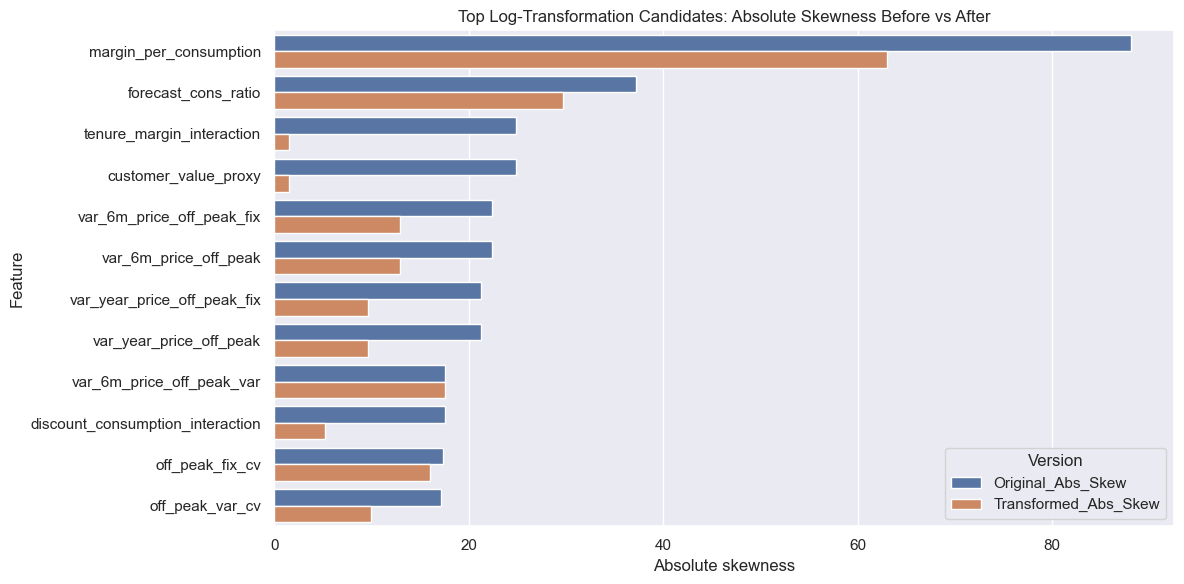

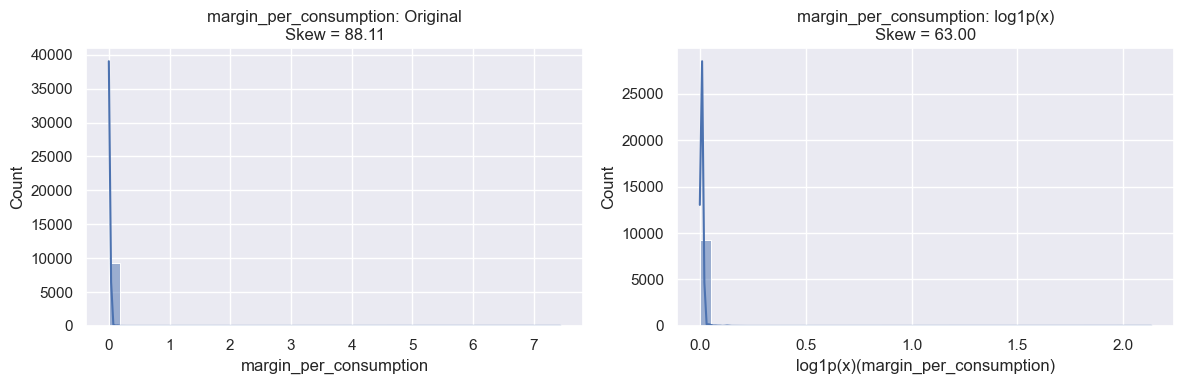

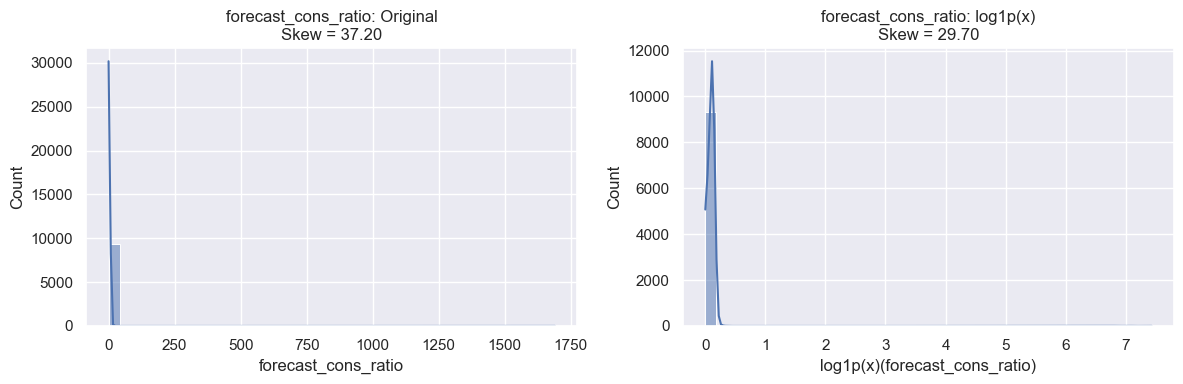

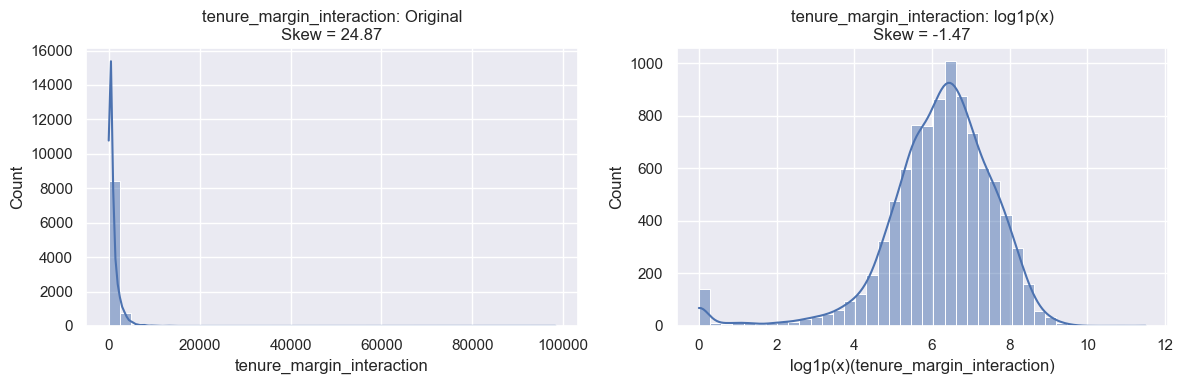

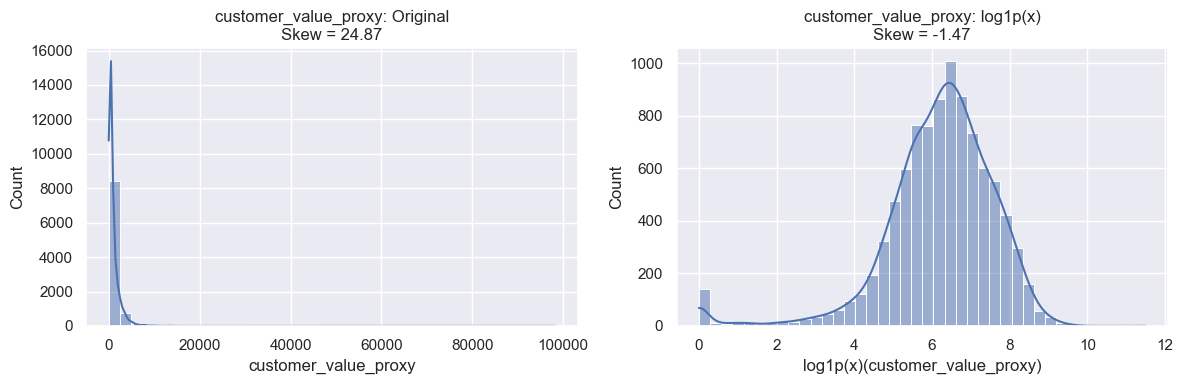

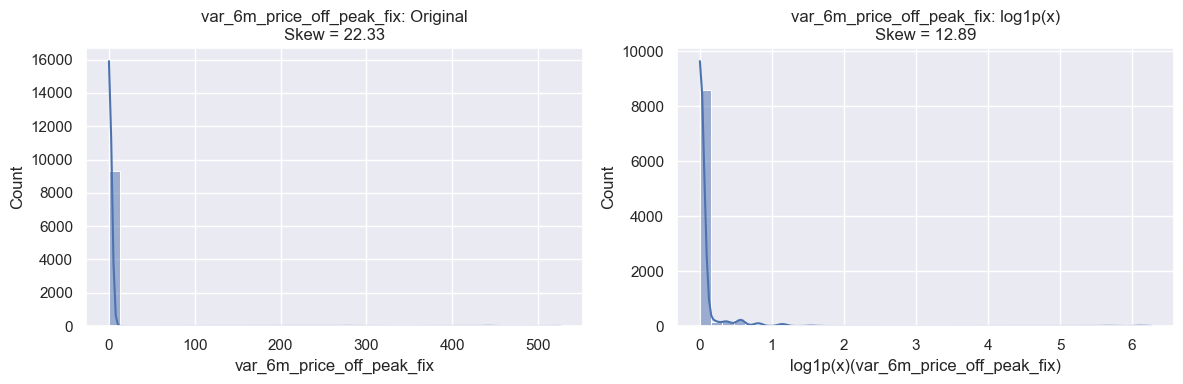

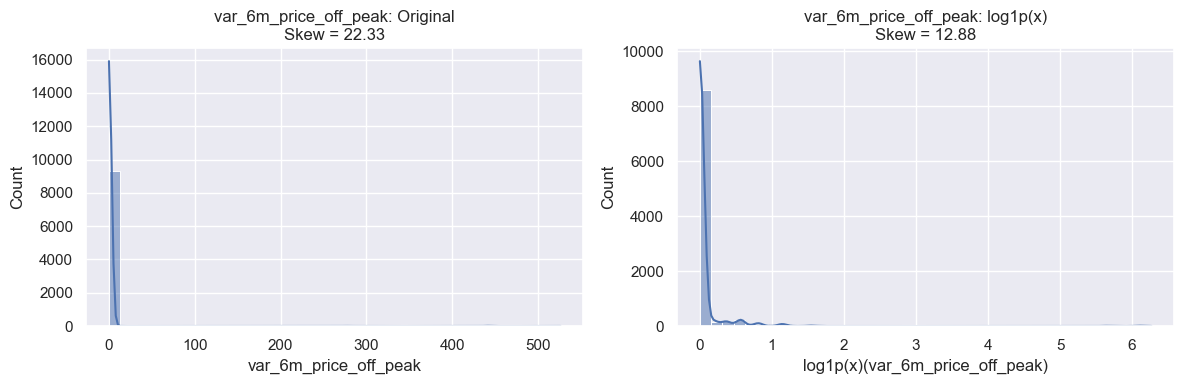


COPY THIS LIST ONLY AFTER REVIEWING THE RESULTS

Non-negative features for log1p:
['margin_per_consumption', 'forecast_cons_ratio', 'tenure_margin_interaction', 'customer_value_proxy', 'var_6m_price_off_peak_fix', 'var_6m_price_off_peak', 'var_year_price_off_peak_fix', 'var_year_price_off_peak', 'var_6m_price_off_peak_var', 'discount_consumption_interaction', 'off_peak_fix_cv', 'off_peak_var_cv', 'var_year_price_off_peak_var', 'var_6m_price_peak', 'var_6m_price_peak_fix', 'cons_gas_12m', 'var_6m_price_mid_peak_fix', 'var_6m_price_mid_peak', 'var_6m_price_mid_peak_var', 'mid_peak_var_cv', 'peak_fix_cv', 'mid_peak_fix_cv', 'var_year_price_peak_var', 'var_6m_price_peak_var', 'forecast_cons_12m', 'var_year_price_mid_peak_var', 'var_year_price_peak', 'var_year_price_peak_fix', 'var_year_price_mid_peak', 'var_year_price_mid_peak_fix', 'margin_per_power', 'cons_last_month', 'product_adoption_rate', 'consumption_per_power', 'margin_net_pow_ele', 'cons_12m', 'gas_product_interaction', 'peak_va

In [65]:
# ============================================================
# EXP2A: LOG-TRANSFORMATION CANDIDATE ANALYSIS
#
# Purpose:
# - Analyze numerical features after Exp2A-style outlier capping
# - Identify skewed continuous features that could benefit from
#   log transformation in a future experiment
# - Does NOT transform or overwrite any data
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split


# ============================================================
# 1. PREPARE FEATURES AND TARGET
# ============================================================

date_cols = [
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal",
]

drop_cols = ["id", "churn"] + [
    col for col in date_cols if col in df.columns
]

X = df.drop(columns=drop_cols, errors="ignore").copy()
y = df["churn"].astype(int).copy()

# Convert infinite values to missing values.
X = X.replace([np.inf, -np.inf], np.nan)

print("=" * 75)
print("EXP2A LOG-TRANSFORMATION CANDIDATE ANALYSIS")
print("=" * 75)
print("Dataset shape:", X.shape)
print("Total missing values:", int(X.isna().sum().sum()))


# ============================================================
# 2. CREATE THE SAME EXP2A SPLITS
#    Analysis uses only model-training data.
# ============================================================

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full,
)

print("\nModel-training shape:", X_model_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)


# ============================================================
# 3. IDENTIFY NUMERIC FEATURES
# ============================================================

numerical_cols = X_model_train.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumber of numerical features:", len(numerical_cols))


# ============================================================
# 4. APPLY EXP2A OUTLIER CAPPING TO TRAINING DATA ONLY
#    This matches the preprocessing used in your prior experiment.
# ============================================================

two_sided_features = [
    "cons_last_month_diff",
    "forecast_cons_diff",
    "price_consumption_exposure",
]

upper_only_features = [
    "consumption_per_power",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product",
]

two_sided_features = [
    col for col in two_sided_features
    if col in X_model_train.columns
]

upper_only_features = [
    col for col in upper_only_features
    if col in X_model_train.columns
]

cap_limits = {}

for col in two_sided_features:
    cap_limits[col] = {
        "lower": X_model_train[col].quantile(0.01),
        "upper": X_model_train[col].quantile(0.99),
    }

for col in upper_only_features:
    cap_limits[col] = {
        "lower": None,
        "upper": X_model_train[col].quantile(0.99),
    }


def apply_capping(data, limits):
    data_out = data.copy()

    for col, bounds in limits.items():
        if col not in data_out.columns:
            continue

        lower_limit = bounds["lower"]
        upper_limit = bounds["upper"]

        if lower_limit is not None:
            data_out[col] = data_out[col].clip(lower=lower_limit)

        if upper_limit is not None:
            data_out[col] = data_out[col].clip(upper=upper_limit)

    return data_out


X_train_capped = apply_capping(X_model_train, cap_limits)


# ============================================================
# 5. HELPER FUNCTION: SIGNED LOG
#
# Safe for negative, zero, and positive values:
# signed_log1p(x) = sign(x) * log(1 + abs(x))
# ============================================================

def signed_log1p(values):
    return np.sign(values) * np.log1p(np.abs(values))


# ============================================================
# 6. ANALYZE EACH NUMERICAL FEATURE
#
# Rules:
# - Skip likely binary / low-cardinality fields.
# - Use log1p for non-negative values.
# - Use signed_log1p when the feature contains negative values.
# - Recommend a transformation only when abs(skew) >= 1.
# ============================================================

analysis_rows = []

for col in numerical_cols:
    values = (
        X_train_capped[col]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if len(values) == 0:
        continue

    unique_count = values.nunique()
    min_value = values.min()
    max_value = values.max()
    zero_pct = 100 * (values == 0).mean()
    negative_pct = 100 * (values < 0).mean()
    positive_pct = 100 * (values > 0).mean()

    original_skew = values.skew()
    original_abs_skew = abs(original_skew)

    # Features with very few values are generally indicators,
    # labels, or discrete values. Do not log-transform them.
    is_low_cardinality = unique_count <= 20

    suggested_transformation = "No log transform"
    transformed_skew = np.nan
    transformed_abs_skew = np.nan
    skew_reduction = np.nan

    if not is_low_cardinality and original_abs_skew >= 1:

        if min_value >= 0:
            transformed_values = np.log1p(values)
            suggested_transformation = "log1p(x)"

        else:
            transformed_values = signed_log1p(values)
            suggested_transformation = "signed_log1p(x)"

        transformed_skew = transformed_values.skew()
        transformed_abs_skew = abs(transformed_skew)
        skew_reduction = original_abs_skew - transformed_abs_skew

        # Do not recommend a transform if it fails to reduce skewness.
        if skew_reduction <= 0:
            suggested_transformation = (
                "No log transform: candidate did not reduce skewness"
            )

    analysis_rows.append({
        "Feature": col,
        "Missing_Pct": 100 * X_train_capped[col].isna().mean(),
        "Unique_Observed": unique_count,
        "Min": min_value,
        "Max": max_value,
        "Zero_Pct": zero_pct,
        "Negative_Pct": negative_pct,
        "Positive_Pct": positive_pct,
        "Original_Skew": original_skew,
        "Original_Abs_Skew": original_abs_skew,
        "Suggested_Transform": suggested_transformation,
        "Transformed_Skew": transformed_skew,
        "Transformed_Abs_Skew": transformed_abs_skew,
        "Abs_Skew_Reduction": skew_reduction,
        "Low_Cardinality": is_low_cardinality,
    })

log_analysis_df = pd.DataFrame(analysis_rows).sort_values(
    by="Original_Abs_Skew",
    ascending=False,
).reset_index(drop=True)


# ============================================================
# 7. SHOW FEATURES RECOMMENDED FOR A LOG EXPERIMENT
# ============================================================

recommended_log_features = log_analysis_df.loc[
    log_analysis_df["Suggested_Transform"].isin(
        ["log1p(x)", "signed_log1p(x)"]
    )
].copy()

print("\n" + "=" * 75)
print("LOG-TRANSFORMATION CANDIDATES")
print("=" * 75)

if recommended_log_features.empty:
    print("No numerical features met the current skewness criteria.")
else:
    print(
        recommended_log_features[
            [
                "Feature",
                "Missing_Pct",
                "Unique_Observed",
                "Min",
                "Max",
                "Zero_Pct",
                "Negative_Pct",
                "Original_Skew",
                "Suggested_Transform",
                "Transformed_Skew",
                "Abs_Skew_Reduction",
            ]
        ].round(4).to_string(index=False)
    )

print("\n" + "=" * 75)
print("TOP 30 FEATURES BY ABSOLUTE SKEWNESS")
print("=" * 75)

print(
    log_analysis_df[
        [
            "Feature",
            "Missing_Pct",
            "Unique_Observed",
            "Min",
            "Max",
            "Original_Skew",
            "Suggested_Transform",
            "Transformed_Skew",
            "Abs_Skew_Reduction",
        ]
    ].head(30).round(4).to_string(index=False)
)


# ============================================================
# 9. PLOT: TOP CANDIDATES BEFORE VS AFTER TRANSFORMATION
# ============================================================

plot_candidates = recommended_log_features.head(12).copy()

if not plot_candidates.empty:
    plot_data = plot_candidates.melt(
        id_vars="Feature",
        value_vars=[
            "Original_Abs_Skew",
            "Transformed_Abs_Skew",
        ],
        var_name="Version",
        value_name="Absolute Skewness",
    )

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=plot_data,
        x="Absolute Skewness",
        y="Feature",
        hue="Version",
    )
    plt.title(
        "Top Log-Transformation Candidates: "
        "Absolute Skewness Before vs After"
    )
    plt.xlabel("Absolute skewness")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


# ============================================================
# 10. PLOT DISTRIBUTIONS FOR THE TOP 6 CANDIDATES
#    This is analysis only. No dataframe columns are changed.
# ============================================================

top_distribution_candidates = recommended_log_features.head(6)

for _, row in top_distribution_candidates.iterrows():
    feature = row["Feature"]

    raw_values = (
        X_train_capped[feature]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if row["Suggested_Transform"] == "log1p(x)":
        transformed_values = np.log1p(raw_values)
        transform_label = "log1p(x)"
    else:
        transformed_values = signed_log1p(raw_values)
        transform_label = "signed_log1p(x)"

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        raw_values,
        bins=40,
        kde=True,
        ax=axes[0],
    )
    axes[0].set_title(
        f"{feature}: Original\nSkew = {raw_values.skew():.2f}"
    )
    axes[0].set_xlabel(feature)

    sns.histplot(
        transformed_values,
        bins=40,
        kde=True,
        ax=axes[1],
    )
    axes[1].set_title(
        f"{feature}: {transform_label}\n"
        f"Skew = {transformed_values.skew():.2f}"
    )
    axes[1].set_xlabel(f"{transform_label}({feature})")

    plt.tight_layout()
    plt.show()


# ============================================================
# 11. FINAL LIST FOR THE NEXT EXPERIMENT
# ============================================================

print("\n" + "=" * 75)
print("COPY THIS LIST ONLY AFTER REVIEWING THE RESULTS")
print("=" * 75)

log1p_features = recommended_log_features.loc[
    recommended_log_features["Suggested_Transform"] == "log1p(x)",
    "Feature",
].tolist()

signed_log_features = recommended_log_features.loc[
    recommended_log_features["Suggested_Transform"] == "signed_log1p(x)",
    "Feature",
].tolist()

print("\nNon-negative features for log1p:")
print(log1p_features)

print("\nFeatures containing negative values for signed_log1p:")
print(signed_log_features)

print(
    "\nAnalysis complete. No transformations have been applied "
    "to df, X_train, X_val, or X_test."
)